<a href="https://colab.research.google.com/github/Gssstabobbdilla/predictor-enfermedades-cardiacas/blob/main/Aprendizaje_Estadistico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
pip install kagglehub[pandas-datasets]

In [2]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

In [3]:
file_path = 'heart.csv'

In [4]:
df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "johnsmith88/heart-disease-dataset",
  file_path,
  # Provide any additional arguments like
  # sql_query or pandas_kwargs. See the
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
)

/tmp/ipykernel_1838/3047778189.py:1: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


Using Colab cache for faster access to the 'heart-disease-dataset' dataset.


# Preprocesamiento de datos

In [5]:
print(df.shape)


(1025, 14)


Contamos con un dataset que contiene 1025 registros y cada uno de ellos contiene 14 columnas

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


Las columnas de nuestro dataset son:

1. **age**: Edad del paciente en años
2. **sex**: Masculino/Femenino
3. **cp**: Tipo de dolor en el pecho - 4 valores
4. **trestbps**: Presión arterial en reposo en mm Hg
5. **chol**: Colesterol sérico en mg/dl
6. **fbs**: Azúcar en sangre en ayunas > 120 mg/dl
7. **restecg**: Resultados electrocardiográficos en reposo - valores 0, 1, 2
8. **thalach**: Frecuencia cardíaca máxima alcanzada
9. **exang**: Angina inducida por el ejercicio
10. **oldpeak**: Depresión del ST inducida por el ejercicio en relación con el reposo
11. **slope**: La pendiente del segmento ST en el ejercicio máximo
12. **ca**: Número de vasos principales (0-3) coloreados por fluoroscopia
13. **thal**:
* 0 = normal
* 1 = defecto fijo
* 2 = defecto reversible
14. **target**: Atributo predicho

In [7]:
df.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


Vemos que ninguna columna contiene datos faltantes

In [8]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


### 1. Tamaño y Demografía de la Muestra

**Edad (`age`):**
* La edad promedio es de 54.4 años (con una mediana de 56 años).
* El rango abarca desde los 29 hasta los 77 años, concentrando al 50% central de los pacientes entre los 48 y 61 años.


**Sexo (`sex`):**
* Con una media de 0.70, existe un desequilibrio de género en la muestra: aproximadamente el 70% son hombres* y el 30% son mujeres.



### 2. Indicadores Clínicos y Cardiovasculares

**Presión arterial en reposo (`trestbps`):**
* La media es de 131.6 mm Hg (mediana de 130), lo cual se encuentra en el límite de la hipertensión leve. Se registran valores máximos de hasta 200 mm Hg.


**Colesterol sérico (`chol`):**
* El promedio es de 246 mg/dl, un valor que supera el límite óptimo recomendado (<200 mg/dl). Destaca un valor máximo extremo de 564 mg/dl, lo que sugiere la presencia de casos severos de hipercolesterolemia u valores atípicos (outliers).


**Frecuencia cardíaca máxima (`thalach`):**
* El promedio alcanzado es de 149.1 latidos por minuto, con un rango amplio que va desde los 71 hasta los 202 bpm.



### 3. Distribución de la Variable Objetivo (`target`)

**Diagnóstico de enfermedad cardíaca:**
* La media de la columna `target` es 0.513, lo que indica que el dataset está muy equilibrado: aproximadamente el 51.3% de los pacientes tienen presencia de enfermedad cardíaca y el 48.7% no la presentan. Esto es ideal para entrenar modelos de aprendizaje automático sin problemas graves de desbalance de clases.

In [9]:
df = df.drop_duplicates()
print(df.shape)

(302, 14)


Inicialmente, el dataset contenía 1025 registros. Tras el proceso de limpieza y filtrado para eliminar filas duplicadas, el conjunto de datos se redujo a 302 registros (manteniendo las 14 columnas originales). Esto implica que se eliminaron 723 registros redundantes (aproximadamente el 70.5% de los datos originales).

In [10]:
print(df["target"].value_counts())
print(df["target"].value_counts(normalize=True))

target
1    164
0    138
Name: count, dtype: int64
target
1    0.543046
0    0.456954
Name: proportion, dtype: float64


A pesar de la reducción significativa del tamaño de la muestra, el dataset continúa manteniendo un equilibrio adecuado para el entrenamiento de modelos de aprendizaje automático:

`Target = 1`: 164 pacientes, lo que representa el 54.3% del total.

`Target = 0`: 138 pacientes, abarcando el 45.7% restante.

In [11]:
df_filtrado = df[df["target"] == 1]
df_filtrado

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
5,58,0,0,100,248,0,0,122,0,1.0,1,0,2,1
10,71,0,0,112,149,0,1,125,0,1.6,1,0,2,1
12,34,0,1,118,210,0,1,192,0,0.7,2,0,2,1
16,51,0,2,140,308,0,0,142,0,1.5,2,1,2,1
18,50,0,1,120,244,0,1,162,0,1.1,2,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
691,55,0,1,135,250,0,0,161,0,1.4,1,0,2,1
708,60,0,2,120,178,1,1,96,0,0.0,2,0,2,1
719,52,1,0,108,233,1,1,147,0,0.1,2,3,3,1
723,68,0,2,120,211,0,0,115,0,1.5,1,0,2,1


## **Análisis exploratorio**

In [12]:
import seaborn as sns
from matplotlib import pyplot as plt

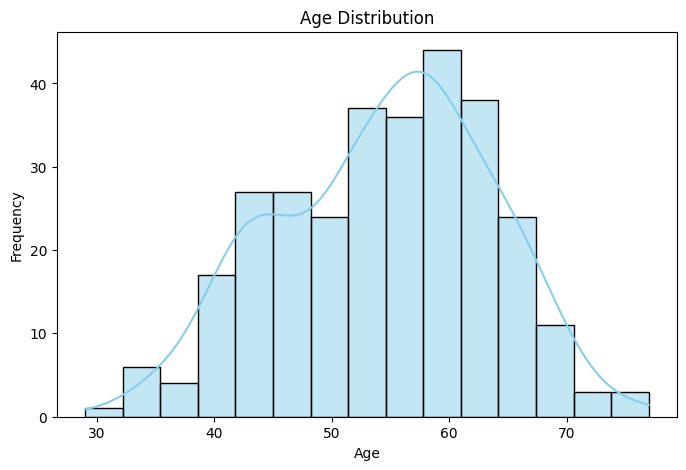

In [13]:
plt.figure(figsize=(8, 5))
sns.histplot(df['age'], bins=15, kde=True, color='skyblue')
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

La mayor concentración de pacientes se encuentra en el rango etario de 50 a 65 años, siendo el intervalo más frecuente el cercano a los 58 años, donde la frecuencia supera los 40 pacientes.

Se observa una baja representación de pacientes en los extremos de la muestra: muy pocos casos por debajo de los 35 años y por encima de los 70 años, lo que indica que el estudio se enfoca principalmente en una población adulta y adulta mayor.

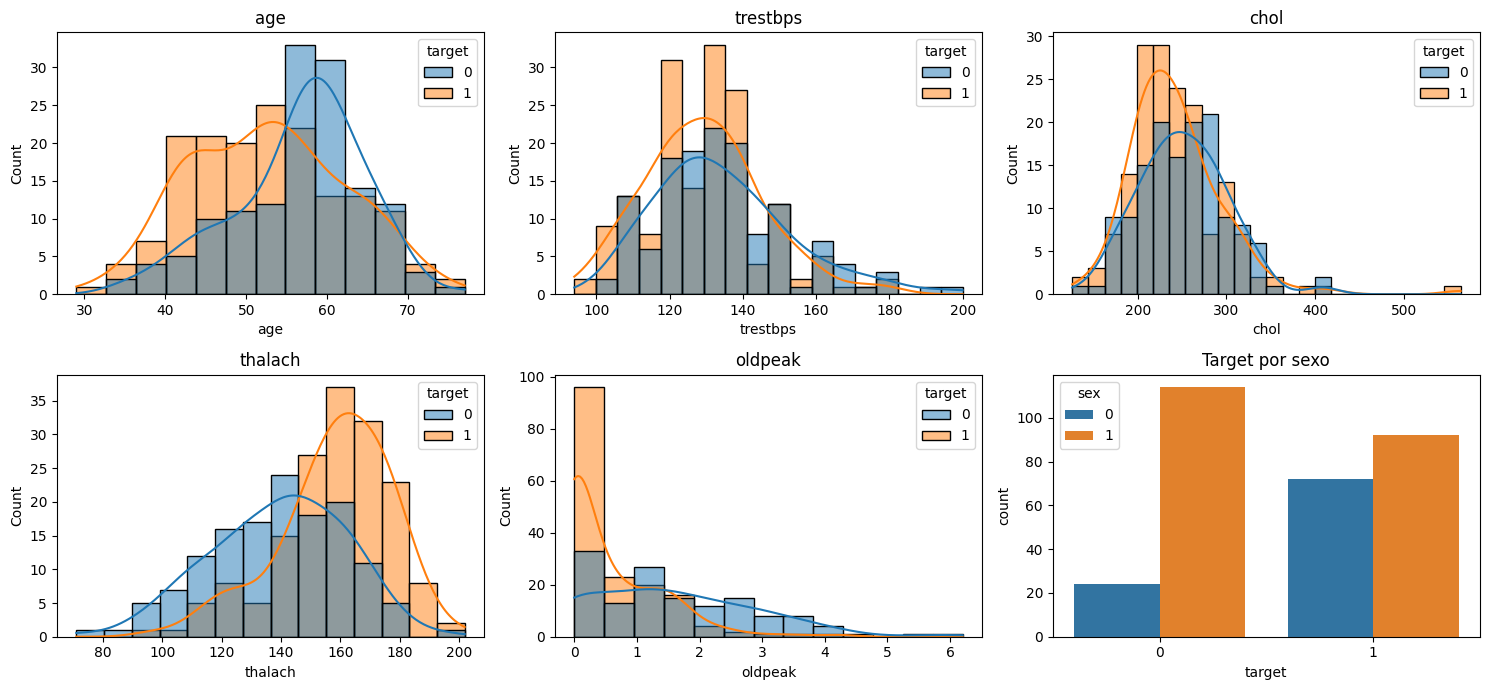

In [14]:
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
ax = ax.flatten()
cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
for i, col in enumerate(cols):
    sns.histplot(
        data=df,
        x=col,
        ax=ax[i],
        kde=True,
        hue='target'
    )
    ax[i].set_title(col)
sns.countplot(
    data=df,
    x='target',
    ax=ax[5],
    hue='sex'
)
ax[5].set_title('Target por sexo')
plt.tight_layout()
plt.show()


**Edad (age) vs. Diagnóstico (target):**

- El gráfico muestra que los pacientes con presencia de enfermedad cardíaca (target = 1, en naranja) se extienden de forma importante en rangos de 40 a 60 años, mientras que el grupo sin enfermedad (target = 0, en azul) concentra su pico principal de manera más marcada en la franja de los 55 a 62 años.

**Presión arterial en reposo (trestbps) vs. Diagnóstico (target):**

- La distribución de la presión arterial en reposo presenta un comportamiento muy similar en ambos grupos, con curvas de densidad casi superpuestas. El pico de concentración para ambos casos se sitúa alrededor de los 120 a 140 mm Hg.

**Colesterol sérico (chol) vs. Diagnóstico (target):**

- Ambas curvas muestran distribuciones altamente superpuestas con un promedio centrado cerca de los 240–260 mg/dl. Destaca un valor atípico (outlier) extremo que supera los 500 mg/dl dentro del grupo con enfermedad cardíaca (target = 1).

**Frecuencia cardíaca máxima (thalach) vs. Diagnóstico (target):**

- Se evidencia una diferencia visual relevante: los pacientes con enfermedad cardíaca (target = 1) alcanzan frecuencias cardíacas máximas más elevadas, concentrándose fuertemente entre los 150 y 170 bpm. En contraste, el grupo sin enfermedad (target = 0) se desplaza hacia valores moderados o más bajos (130–140 bpm).

**Depresión del ST (oldpeak) vs. Diagnóstico (target):**

- Se observa una alta concentración de valores cercanos a 0 en ambos grupos, siendo especialmente pronunciada en los pacientes diagnosticados con la enfermedad (target = 1). Los valores superiores a 2.0 disminuyen de manera progresiva en ambas categorías.

**Relación entre la Variable Objetivo (target) y el Sexo (sex):**

- El gráfico de barras agrupadas expone el comportamiento por género frente al diagnóstico. En el caso de los hombres (sex = 1, naranja), la cantidad de pacientes es ampliamente superior en ambas clases, registrando un volumen alto tanto en ausencias como en presencias de enfermedad. Por su parte, las mujeres (sex = 0, azul) muestran una proporción menor en el dataset, con una presencia notablemente más alta de diagnósticos positivos en comparación con los negativos.

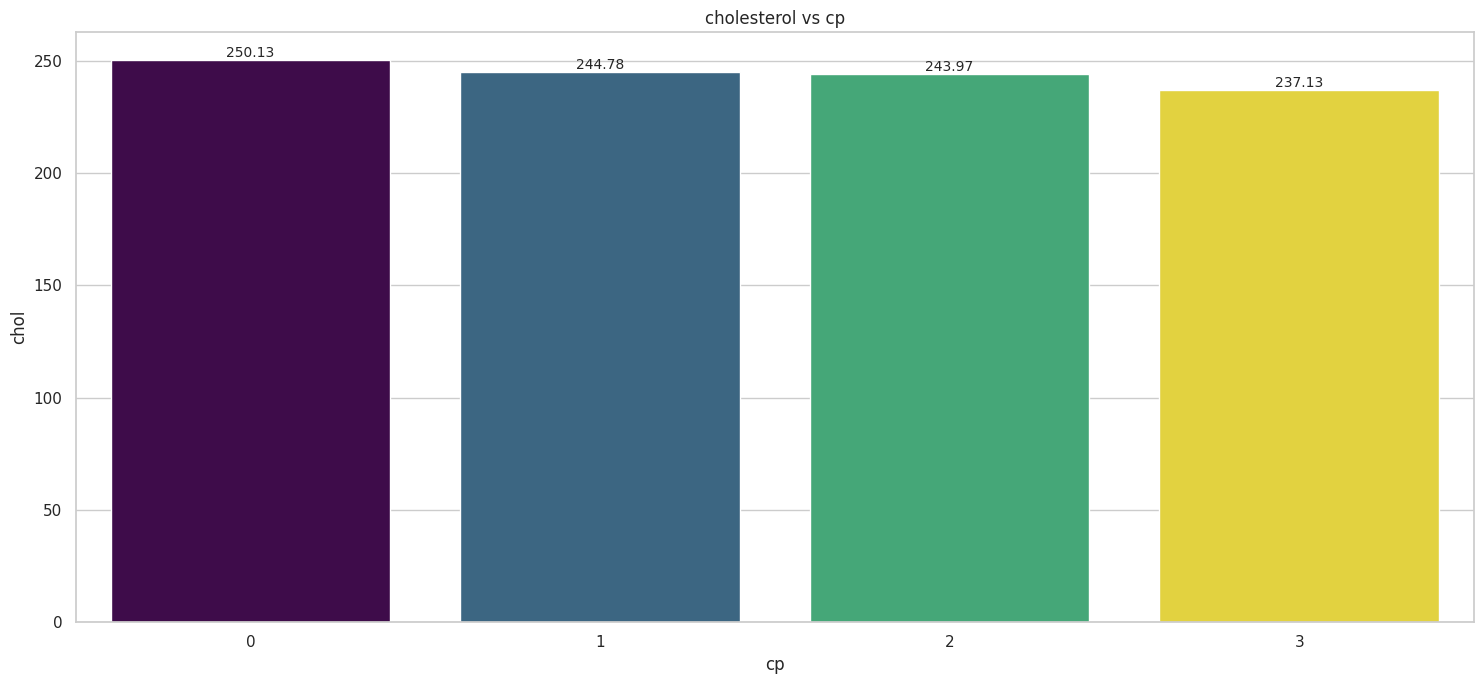

In [15]:
chol_means = df.groupby('cp')['chol'].mean().round(2).reset_index()

sns.set_theme(style="whitegrid")
plt.figure(figsize=(15, 7))

ax = sns.barplot(
    data=chol_means,
    x='cp',
    y='chol',
    palette='viridis',
    hue='cp',
    legend=False
)

plt.title('cholesterol vs cp')
plt.xlabel('cp')
plt.ylabel('chol')

for p in ax.patches:
    ax.annotate(
        format(p.get_height(), '.2f'),
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center',
        va='center',
        xytext=(0, 5),
        textcoords='offset points',
        fontsize=10
    )

plt.tight_layout()
plt.show()

La categoría 0 registra el promedio de colesterol más elevado (250.13 mg/dl), mientras que la categoría 3 presenta el valor medio más bajo (237.13 mg/dl). Esta ligera variación sugiere que, de forma aislada, el nivel de colesterol sérico por sí solo no muestra una diferencia drástica o determinante entre los distintos tipos de dolor torácico reportados por los pacientes.

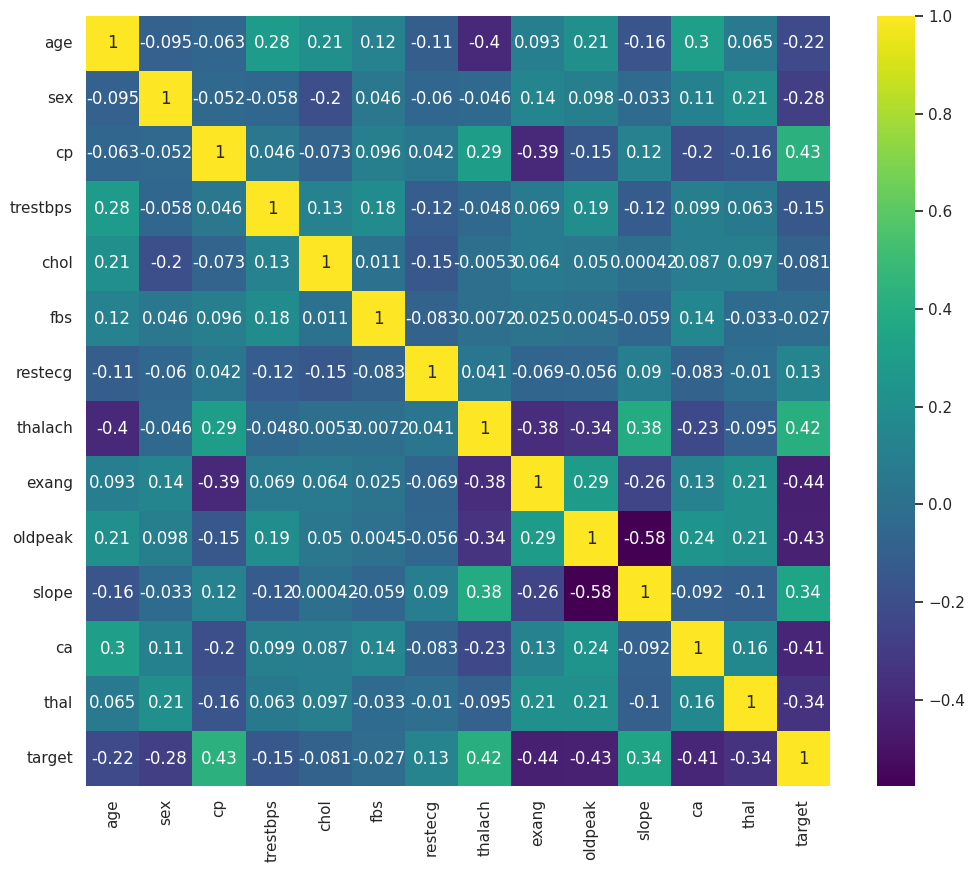

In [16]:
plt.figure(figsize=(12,10))
sns.heatmap(df.select_dtypes('number').corr(),cmap='viridis',annot=True)
plt.show()

Las variables `cp` (tipo de dolor en el pecho), `thalach` (frecuencia cardíaca máxima) y `slope` presentan las correlaciones positivas más destacadas con la presencia de enfermedad cardíaca, con valores de 0.43, 0.42 y 0.34 respectivamente.   

Por el contrario, variables como `exang` (-0.44), `oldpeak` (-0.43), `ca` (-0.41), `thal` (-0.34), `sex` (-0.28) y `age` (-0.22) muestran correlaciones negativas moderadas respecto al target.

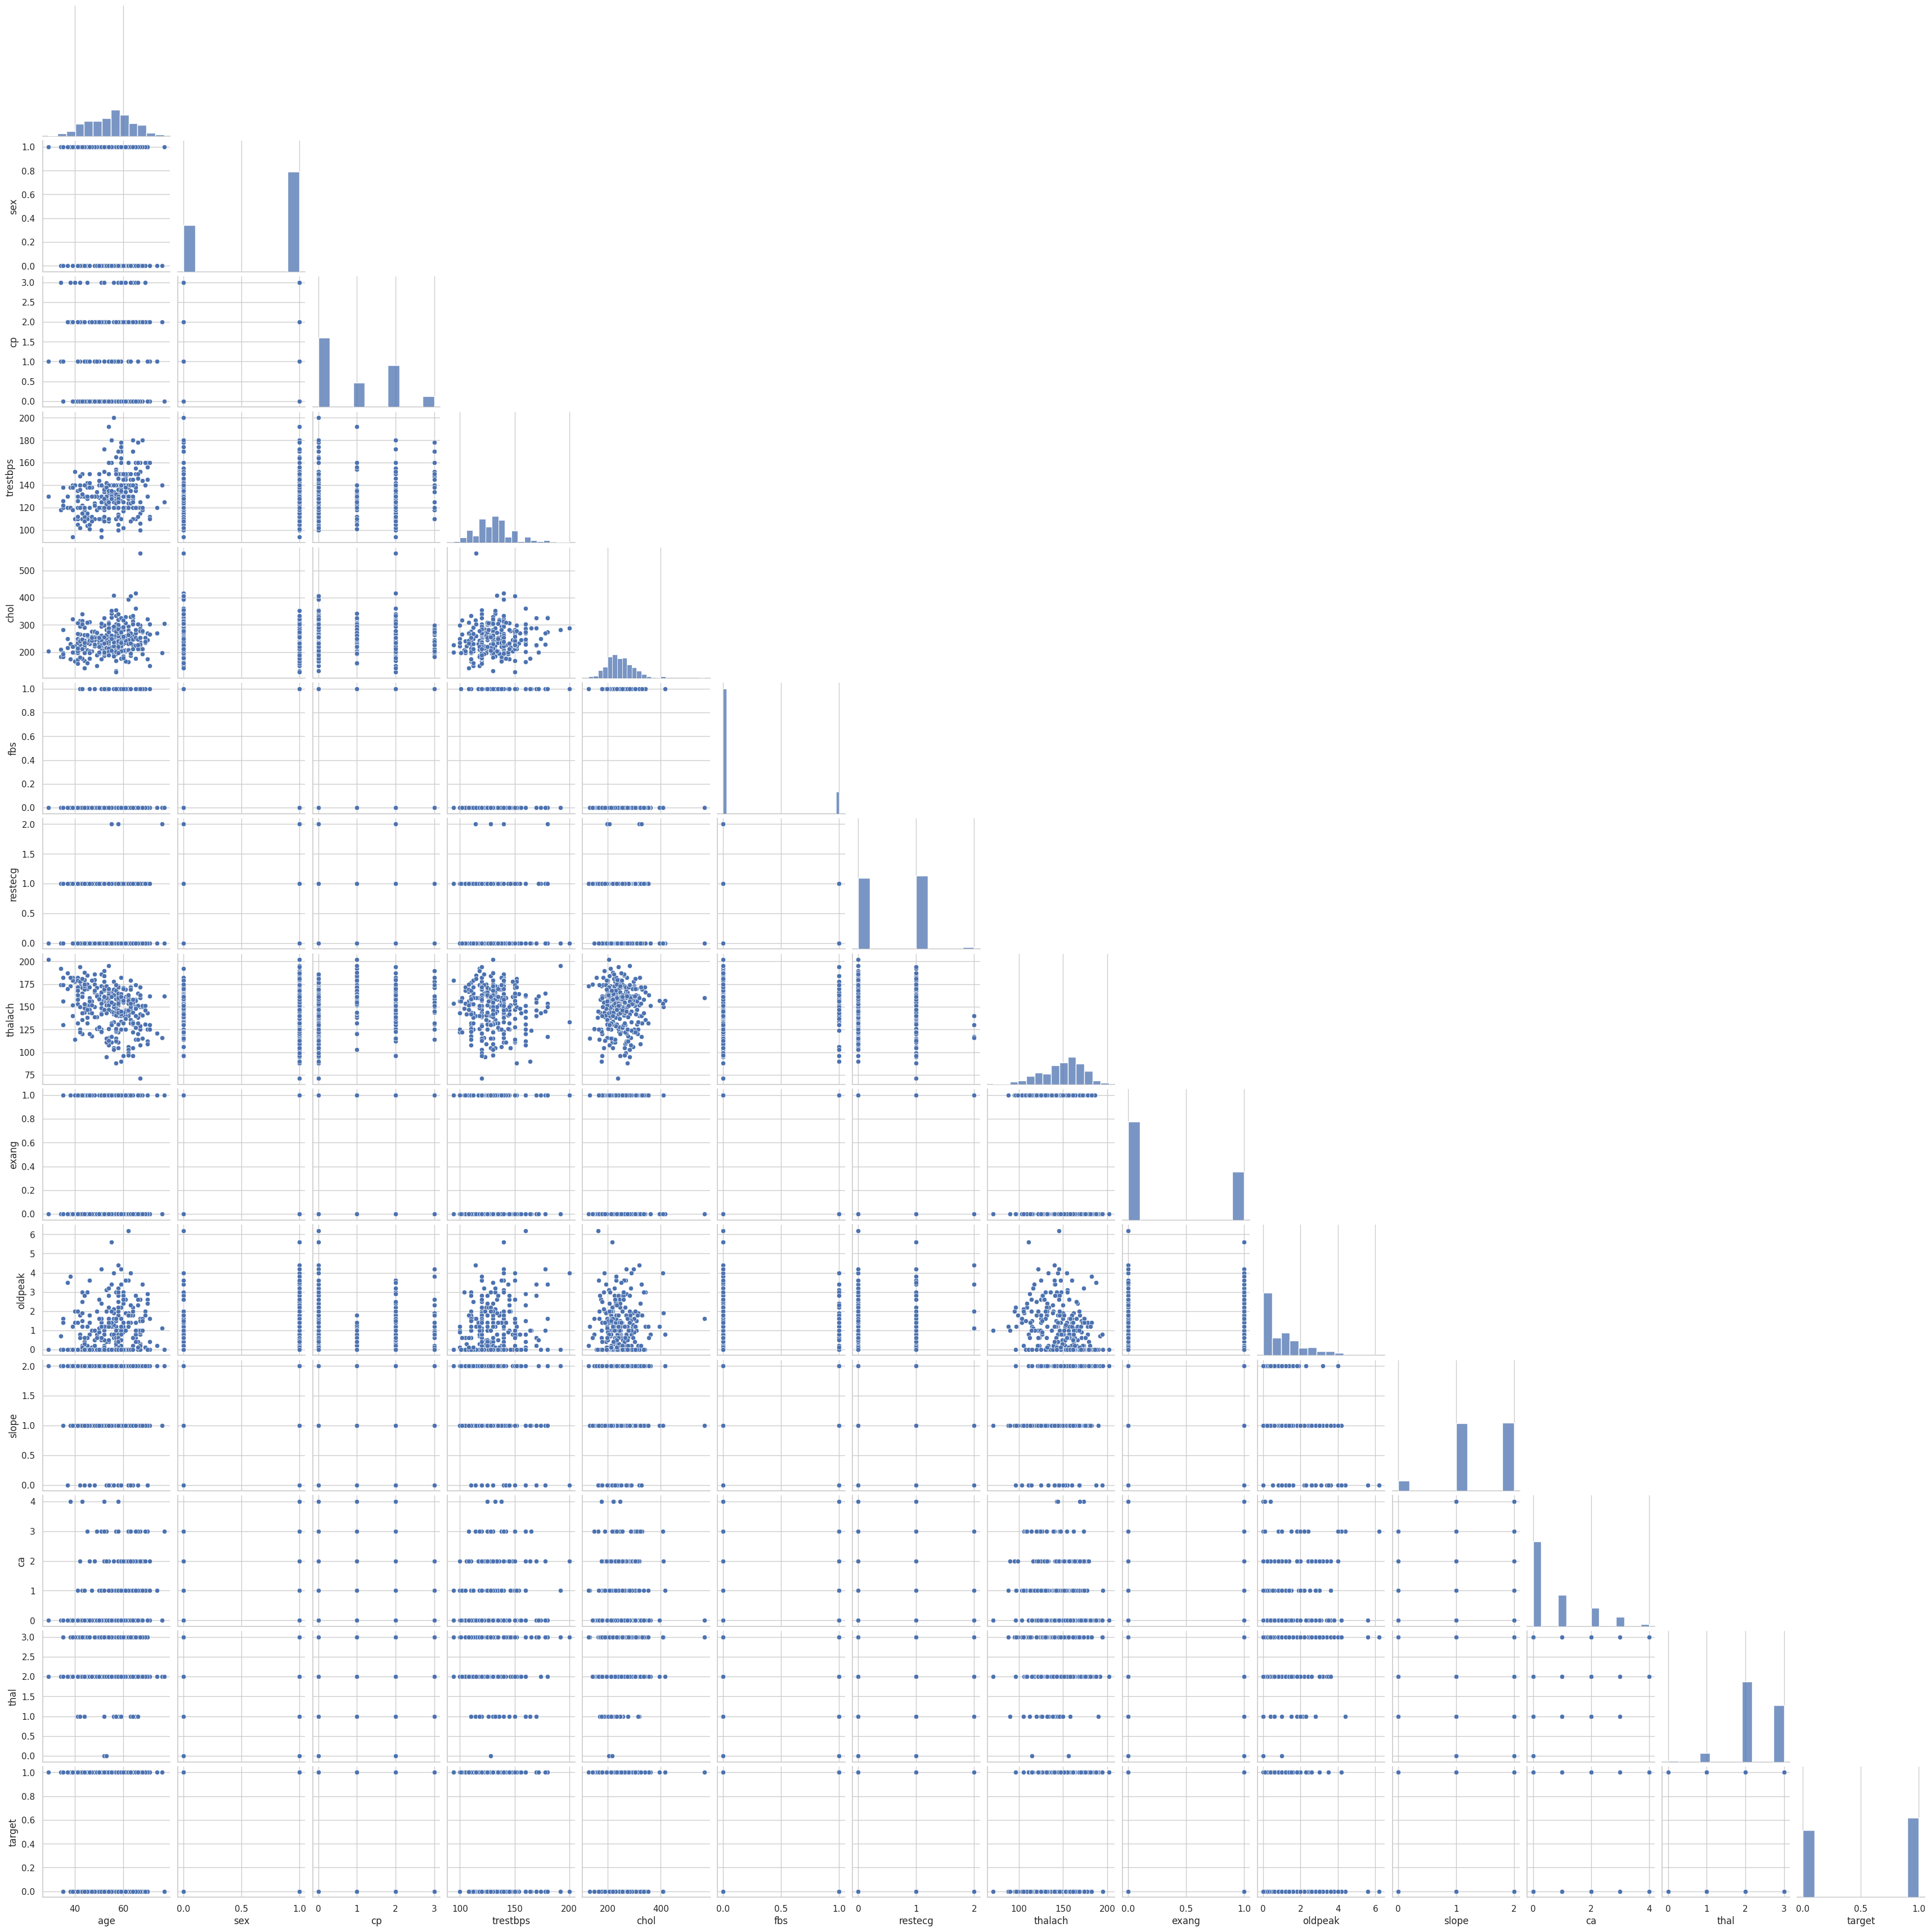

In [17]:
sns.pairplot(data=df,corner=True)
plt.show()

## **Planteamiento del Data-Set de Entrenamiento y Prueba**

Tras la limpieza de duplicados, el conjunto de datos quedó reducido a 302 observaciones únicas. Dado este tamaño de muestra relativamente pequeño, dividir los datos en tres subconjuntos fijos (entrenamiento, validación y prueba) reduciría considerablemente el número de observaciones disponibles para cada etapa, afectando la estabilidad de las estimaciones.

Por este motivo, se plantea la siguiente estrategia:

- **Data-Set de entrenamiento (training):** 80 % de las observaciones (241 registros), obtenido mediante `train_test_split` con muestreo estratificado (`stratify=y`) para conservar la proporción original de la variable `target` (54.3 % / 45.7 %).
- **Data-Set de prueba (test):** 20 % de las observaciones (61 registros), reservado exclusivamente para la evaluación final del modelo seleccionado, sin participar en ninguna etapa de ajuste o selección de hiperparámetros.


In [18]:
from sklearn.model_selection import train_test_split

In [19]:
X = df.drop(columns=["target"])
y = df["target"]

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

In [21]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\nDistribución Train:")
print(y_train.value_counts(normalize=True))

print("\nDistribución Test:")
print(y_test.value_counts(normalize=True))

X_train: (241, 13)
X_test: (61, 13)

Distribución Train:
target
1    0.543568
0    0.456432
Name: proportion, dtype: float64

Distribución Test:
target
1    0.540984
0    0.459016
Name: proportion, dtype: float64


## **Estandarización de variables continuas**

Las variables continuas `age`, `trestbps`, `chol`, `thalach` y `oldpeak` se encuentran en escalas de medición muy distintas entre sí (por ejemplo, el colesterol se mide en mg/dl mientras que la edad se expresa en años). Por ello, se aplica `StandardScaler` para transformar cada variable continua de modo que tenga media 0 y desviación estándar 1.

El escalador se ajusta (`fit`) **únicamente sobre el conjunto de entrenamiento** y luego se aplica (`transform`) sobre el conjunto de prueba, con el fin de evitar fuga de información (*data leakage*) entre el entrenamiento y la evaluación del modelo.

In [22]:
from sklearn.preprocessing import StandardScaler

cont_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[cont_cols] = scaler.fit_transform(X_train[cont_cols])
X_test_scaled[cont_cols] = scaler.transform(X_test[cont_cols])

In [23]:
X_train_scaled[cont_cols].describe().loc[['mean', 'std']]

,age,trestbps,chol,thalach,oldpeak
mean,-3.316849e-16,-7.849876e-16,4.791004e-17,2.948310e-16,-1.474155e-17
std,1.002081e+00,1.002081e+00,1.002081e+00,1.002081e+00,1.002081e+00


## **Data-Set de validación (Cross-Validation)**
 En lugar de reservar un tercer subconjunto fijo, la validación se realiza mediante **validación cruzada estratificada (`StratifiedKFold`, k = 5)** aplicada exclusivamente sobre el conjunto de entrenamiento. En cada iteración, el 80 % de los datos de entrenamiento se usa para ajustar el modelo y el 20 % restante actúa como conjunto de validación, rotando en cada uno de los 5 folds. Esto permite aprovechar mejor la información disponible y obtener una estimación más robusta y menos dependiente de una única partición aleatoria.

In [24]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for fold, (train_idx, val_idx) in enumerate(cv.split(X_train_scaled, y_train), start=1):
    print(f"Fold {fold}: entrenamiento = {len(train_idx)} muestras | validación = {len(val_idx)} muestras")

Fold 1: entrenamiento = 192 muestras | validación = 49 muestras
Fold 2: entrenamiento = 193 muestras | validación = 48 muestras
Fold 3: entrenamiento = 193 muestras | validación = 48 muestras
Fold 4: entrenamiento = 193 muestras | validación = 48 muestras
Fold 5: entrenamiento = 193 muestras | validación = 48 muestras


## **Resumen de los Data-Sets planteados**

| Data-Set | Tamaño | Rol |
|---|---|---|
| Entrenamiento (`X_train_scaled`, `y_train`) | 241 obs. (80 %) | Ajuste de los modelos y validación cruzada (k = 5) |
| Validación (folds de `StratifiedKFold`, k = 5) | ~48-49 obs. por fold | Selección de modelos e hiperparámetros dentro del entrenamiento |
| Prueba (`X_test_scaled`, `y_test`) | 61 obs. (20 %) | Evaluación final, únicamente al finalizar la selección del modelo |


Con este planteamiento, el conjunto de prueba permanece completamente aislado del proceso de entrenamiento y selección de modelos, mientras que la validación cruzada aprovecha de forma eficiente las 241 observaciones de entrenamiento disponibles.

### **Verificación del esquema de validación**

Para comprobar que el esquema de partición funciona correctamente, se aplica un modelo de referencia simple (Regresión Logística) sobre las 5 particiones de validación cruzada. Este resultado es solo ilustrativo del mecanismo de validación; el desarrollo, ajuste y comparación formal de los modelos (incluyendo XGBoost) se aborda en la sección IV (Aprendizaje).

In [25]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

modelo_referencia = LogisticRegression(max_iter=1000, random_state=42)
scores_val = cross_val_score(modelo_referencia, X_train_scaled, y_train, cv=cv, scoring='accuracy')

print("Accuracy por fold:", np.round(scores_val, 3))
print(f"Accuracy promedio (validación cruzada): {scores_val.mean():.3f} +/- {scores_val.std():.3f}")

Accuracy por fold: [0.918 0.792 0.833 0.958 0.708]
Accuracy promedio (validación cruzada): 0.842 +/- 0.089


# **IV. Aprendizaje**

## **4.1 Planteamiento del Modelo de Aprendizaje**

El problema se plantea como **aprendizaje supervisado de clasificación binaria**: se dispone de observaciones con una etiqueta conocida (`target`: 0 = ausencia, 1 = presencia de enfermedad cardíaca) y el objetivo es aprender una regla $\hat{y} = f(x)$, con $x$ el vector de 13 variables clínicas, que generalice a pacientes nuevos. No se usa aprendizaje no supervisado porque la variable de respuesta está disponible.

**Familias de modelos** (de menor a mayor flexibilidad, según el objetivo específico 1.4.2.3):

| Modelo | Tipo | Motivo de inclusión |
|---|---|---|
| Regresión logística sin regularización | Lineal | Línea base interpretable |
| Regresión logística con penalización L2 (*Ridge*) | Lineal regularizado | Reduce la varianza si hay predictores correlacionados |
| Regresión logística con penalización L1 (*Lasso*) | Lineal regularizado | Permite selección de variables |
| Random Forest | No lineal (*bagging*) | Captura interacciones con baja varianza |
| XGBoost | No lineal (*boosting*) | Modelo de ensamble con regularización explícita |

**Estrategia de entrenamiento y selección**

- Los hiperparámetros se ajustan con `GridSearchCV` sobre el **Data-Set de entrenamiento** usando la validación cruzada estratificada de 5 folds definida en la sección 3.3 (`cv`); el modelo de cada familia se elige por **F1**.
- Métricas: *accuracy*, *precision*, *recall* (sensibilidad), *F1* y *ROC-AUC*. Dado que un falso negativo (paciente enfermo clasificado como sano) es el error más costoso, se presta especial atención al *recall*. El objetivo 1.4.2.4 exige precisión y sensibilidad superiores al 80 %.
- Para comparar las familias de forma más estable se repite la validación cruzada 5 veces (`RepeatedStratifiedKFold`, 5×5 = 25 evaluaciones por modelo).
- El **Data-Set de prueba no se utiliza en esta sección**: queda reservado para la evaluación final (secciones V y VI).

# **Modelos a implementar**

## **XGBoost**

  XGNoost es la abreviatura de *Extreme Gradient Bosting*, es un algoritmo de aprendizaje supervisado basado en la técnica de *gradient boosting mediante árboles de decisión.* Consiste en construir un modelo predictivo mediante la combinación secuencial de múltiples árboles, donde cada nuevo árbol intenta corregir los errores cometidos por el conjunto de árboles construidos anteriormente.
  XGBoost pertenece a los denominados *métodos de ensamble*, es decir, métodos que combinan varios modelos relativamente simples con el objetivo de obtener un modelo final con mayor capacidad predictiva.


  
  Dentro de los métodos de ensamble están los métodos de *bagging* y *boosting*. En los métodos de boosting, los modelos se construyen secuaneicalmente

  $f_1(x) \to f_2(x) \to f_3(x) \to \dots f_K(x)$

  Cada nuevo modelo se incorpora intentando mejorar los errores que todavía presenta el conjunto anterior.

  El modelod e XGBoost está basado en **Gradient Tree Boosting**. El modelo final no está formado por un único árbol, sino por la suma de las predicciones producidas por varios árboles.

  $\hat{y}_i = ϕ(x_i​)= \sum_{K=1}^K f_k(x_i)$

  Por tanto, cada árbol aporta una determinada contribución a la predicción final.
  Este punto es importante porque XGBoost no trabaja como un árbol de decisión convencional. En un árbol individual tendríamos
  
  $x_i​→ arbol → \hat{y}_i$

  En XGBoost lo que tenemos es

  $
    x_i \to
    \begin{cases}
      f_1(x) \\
      f_2(x) \\
      \vdots \\
      f_K(x)     
    \end{cases}
    \to
    \sum_{K=1}^K f_k(x_i)
  $

  Una de las ideas fundamentales de boosting es que los arboles no se construyen de manera independiente. Por ejemplo, si después de $t-1$ itearciones la predicción del modelo es
  
  $\hat{y}_i^{(t-1)}$

  Entonces XGBoost incorpora un nuevo árbol $f_1(x)$, produciendo así

  $\hat{y}_i^{(t)} = \hat{y}_i^{(t-1)} + f_t(x_i)$

  El objetivo del nuevo árbol donsiste en mejorar el modelo existente. Por lo tanto, podemso representar el procedimiento como

  $
    \begin{align*}
      \hat{y}^{(0)} & \\
      \downarrow & \\
      \hat{y}^{(1)} &= \hat{y}^{(0)} + f_1(x) \\
      \downarrow & \\
      \hat{y}^{(2)} &= \hat{y}^{(1)} + f_2(x) \\
      \downarrow & \\
      \dots & \\
      \downarrow & \\
      \hat{y}^{(K)} &= \sum_{k=1}^{K} f_k(x).
  \end{align*}
  $

  Así, cada iteración intenta reducir la función de pérdida obtenida hasta ese momento.

### **1.3. Función Objetivo**

Una de las características más importantes de XGBoost es que no busca únicamente minimizar el error predictivo. El modelo considera una función objetivo formada por los siguientes componentes

$ \text{Función Objetivo} = \text{Error del modelo} + \text{Complejidad del modelo} $

Chen y Guestrin la expresan como

$ \mathcal{L}(\phi) = \sum_{i} l(\hat{y}_i, y_i) + \sum_{k} \Omega(f_k) $

Donde:


*   $l(\hat{y}_i, y_i)$ es una función de pérdida que mide la diferencia entre la predicción y el valor real
*   $\Omega(f_k)$ es un término de regularización que penaliza la complejidad de los árboles.

Para cada arbol

$\Omega(f) = \gamma T + \frac{1}{2}\lambda \| w \|^2$

Donde:



*   $T$ es el número de hojas del árbol
*   $w$ representa los pesos asignados a las hojas
*   $\gamma$ penaliza la creación de nuevas hojas
*   $\lambda$ controla la magnitud de los pesos.

Intuitivamente:

$ \text{modelo demasiado complejo} \Longrightarrow \text{mayor penalización}$

De esta manera, el algoritmo intenta encontrar un equilibrio entre el ajuste a los datos y la simplicidad del modelo.

## **Regresión logística y regularización**

La regresión logística modela la probabilidad de la clase positiva como

$P(y=1 \mid x) = \dfrac{1}{1 + e^{-(\beta_0 + \beta^\top x)}}$

y estima $\beta$ maximizando la verosimilitud. La **regularización** añade una penalización a la función de pérdida:

- **L2 (Ridge):** $\lambda \sum_j \beta_j^2$ — contrae los coeficientes hacia cero sin anularlos.
- **L1 (Lasso):** $\lambda \sum_j |\beta_j|$ — puede anular coeficientes, realizando selección de variables.

En `scikit-learn` la fuerza de la penalización se controla con $C = 1/\lambda$: **valores pequeños de $C$ implican mayor regularización**. Como los predictores continuos ya están estandarizados (sección 3.2.3), los coeficientes son comparables entre sí.

## **Random Forest**

Random Forest es un método de ensamble basado en *bagging*: entrena muchos árboles de decisión sobre muestras *bootstrap* de los datos y, en cada división, considera solo un subconjunto aleatorio de variables (`max_features`). La predicción final es el promedio (voto) de los árboles. A diferencia del *boosting* de XGBoost, los árboles se construyen **de forma independiente**, lo que reduce principalmente la **varianza**. Los hiperparámetros más relevantes con pocos datos son la profundidad máxima (`max_depth`) y el tamaño mínimo de hoja (`min_samples_leaf`).

## **Support Vector Machine (SVM)**

Una SVM busca el hiperplano que separa las dos clases con el **mayor margen posible**. Con clases que se solapan se usa un margen blando, donde el parámetro $C$ controla el compromiso entre un margen amplio y los errores de clasificación permitidos (**$C$ grande = menos tolerancia a errores = modelo más flexible**).

Para fronteras no lineales se usa el **kernel RBF** (función de base radial):

$K(x, x') = \exp\left(-\gamma \, \|x - x'\|^2\right)$

El parámetro $\gamma$ define la influencia de cada observación: **$\gamma$ grande produce fronteras muy locales (riesgo de sobreajuste)** y $\gamma$ pequeño fronteras más suaves. Como el kernel se basa en distancias, la SVM es sensible a la escala de las variables, por lo que la estandarización de la sección 3.2.3 es necesaria. Con `probability=True`, `scikit-learn` calibra las probabilidades mediante escalamiento de Platt, necesario para curvas ROC y probabilidades de clase.

## **4.2 Desarrollo e Implementación del Modelo**

Se implementan los cinco modelos con la misma partición: ajuste y validación cruzada **solo sobre `X_train_scaled` / `y_train`**.

In [26]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

scoring = {'accuracy': 'accuracy', 'precision': 'precision', 'recall': 'recall',
           'f1': 'f1', 'roc_auc': 'roc_auc'}

def resumen_cv(modelo, nombre, cv_=cv):
    r = cross_validate(modelo, X_train_scaled, y_train, cv=cv_, scoring=scoring)
    return pd.Series({m: r[f'test_{m}'].mean() for m in scoring}, name=nombre)

def buscar(estimador, grid):
    gs = GridSearchCV(estimador, grid, cv=cv, scoring=scoring, refit='f1', n_jobs=-1)
    gs.fit(X_train_scaled, y_train)
    return gs

### **Modelo 1: Regresión logística sin regularización (línea base)**

In [27]:
lr_base = LogisticRegression(penalty=None, max_iter=5000)
resumen_cv(lr_base, 'LR sin regularización').round(3).to_frame().T

,accuracy,precision,recall,f1,roc_auc
LR sin regularización,0.838,0.835,0.893,0.859,0.914


La regresión logística sin regularización, validada con los 5 folds de la sección 3.3, alcanza una *accuracy* de 0.838, *precision* de 0.835, *recall* de 0.893, *F1* de 0.859 y *ROC-AUC* de 0.914.

El *recall* supera a la *precision*: el modelo detecta mejor a los pacientes enfermos de lo que evita falsas alarmas, lo cual es deseable en este problema donde el falso negativo es el error más costoso.

### **Modelos 2 y 3: Regresión logística con penalización L2 y L1**

Se busca el valor de $C$ en una rejilla logarítmica de 20 valores entre $10^{-3}$ y $10^{2}$.

L2 -> mejor C = 4.833 | F1 (CV) = 0.866
L1 -> mejor C = 4.833 | F1 (CV) = 0.866


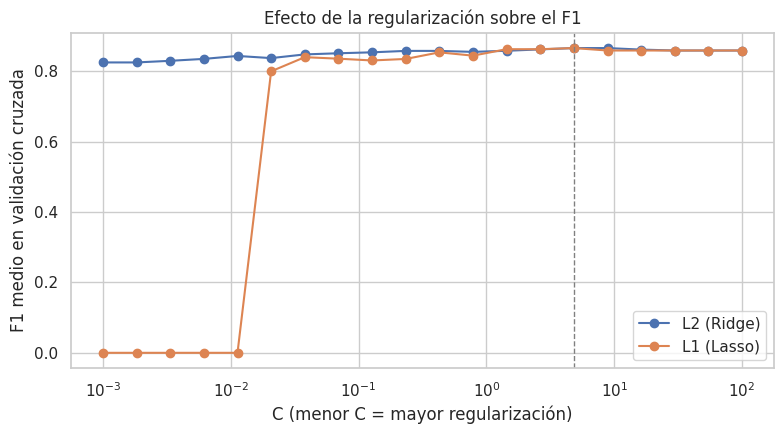

In [28]:
param_C = {'C': np.logspace(-3, 2, 20)}

gs_l2 = buscar(LogisticRegression(penalty='l2', solver='liblinear', max_iter=5000), param_C)
gs_l1 = buscar(LogisticRegression(penalty='l1', solver='liblinear', max_iter=5000), param_C)

print(f"L2 -> mejor C = {gs_l2.best_params_['C']:.3f} | F1 (CV) = {gs_l2.best_score_:.3f}")
print(f"L1 -> mejor C = {gs_l1.best_params_['C']:.3f} | F1 (CV) = {gs_l1.best_score_:.3f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
for gs, nombre in [(gs_l2, 'L2 (Ridge)'), (gs_l1, 'L1 (Lasso)')]:
    ax.semilogx(param_C['C'], gs.cv_results_['mean_test_f1'], marker='o', label=nombre)
ax.axvline(gs_l1.best_params_['C'], color='gray', linestyle='--', linewidth=1)
ax.set_xlabel('C (menor C = mayor regularización)')
ax.set_ylabel('F1 medio en validación cruzada')
ax.set_title('Efecto de la regularización sobre el F1')
ax.legend()
plt.tight_layout()
plt.show()

**Análisis.** Tanto L2 como L1 eligen el mismo valor $C = 4.83$ con un F1 de validación de 0.866, apenas por encima de la línea base (0.859). La curva es prácticamente plana para $C \gtrsim 0.5$: con 241 observaciones y 13 predictores el modelo lineal no sobreajusta de forma importante, por lo que **la regularización aporta poco en este conjunto**. A mayor regularización las dos penalizaciones se comportan distinto: L2 pierde rendimiento de forma gradual (F1 ≈ 0.82 con $C = 10^{-3}$), mientras que L1 colapsa a F1 = 0 para $C \lesssim 0.01$, porque todos los coeficientes se anulan y el modelo deja de predecir la clase positiva.

### **Selección de variables con L1: trayectoria de regularización**

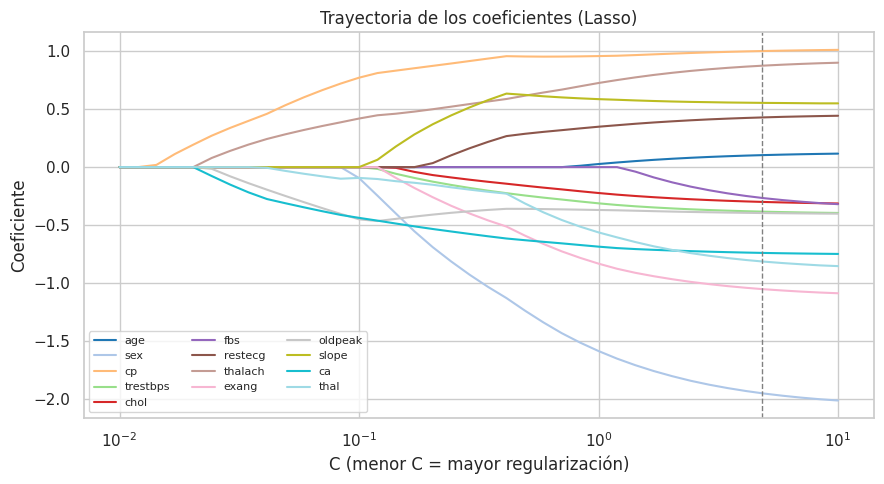

Orden de entrada al modelo (C mínimo con coeficiente != 0):
cp          0.014
thalach     0.024
ca          0.024
oldpeak     0.024
thal        0.041
sex         0.100
slope       0.119
trestbps    0.119
exang       0.143
chol        0.143
restecg     0.203
age         0.838
fbs         1.425


In [29]:
Cs = np.logspace(-2, 1, 40)
coefs = []
for c in Cs:
    m = LogisticRegression(penalty='l1', solver='liblinear', C=c, max_iter=5000).fit(X_train_scaled, y_train)
    coefs.append(m.coef_[0])
coefs = pd.DataFrame(coefs, index=Cs, columns=X_train_scaled.columns)

fig, ax = plt.subplots(figsize=(9, 5))
paleta = plt.cm.tab20(np.linspace(0, 1, len(coefs.columns)))
for col, color in zip(coefs.columns, paleta):
    ax.semilogx(coefs.index, coefs[col], label=col, color=color)
ax.axvline(gs_l1.best_params_['C'], color='gray', linestyle='--', linewidth=1)
ax.set_xlabel('C (menor C = mayor regularización)')
ax.set_ylabel('Coeficiente')
ax.set_title('Trayectoria de los coeficientes (Lasso)')
ax.legend(ncol=3, fontsize=8)
plt.tight_layout()
plt.show()

# Primer valor de C (de menor a mayor) en que cada variable entra al modelo
entrada = {col: (coefs.index[(coefs[col] != 0).values][0] if (coefs[col] != 0).any() else np.nan) for col in coefs.columns}
print("Orden de entrada al modelo (C mínimo con coeficiente != 0):")
print(pd.Series(entrada).sort_values().round(3).to_string())

**Análisis.** La trayectoria muestra el orden en que Lasso incorpora las variables al aumentar $C$: primero `cp` ($C = 0.014$), luego `thalach`, `ca` y `oldpeak` ($0.024$), `thal` ($0.041$) y `sex` ($0.100$); `age` ($0.838$) y `fbs` ($1.425$) entran al final. Es decir, `cp`, `thalach`, `ca`, `oldpeak` y `thal` son las más informativas **una vez controladas las demás**, mientras que `age` y `fbs` aportan poco. Esto es coherente con el análisis exploratorio, donde `cp` y `thalach` mostraban las correlaciones positivas más altas con el diagnóstico y `exang`, `oldpeak` y `ca` las negativas. En el $C$ óptimo (línea punteada) los 13 coeficientes son distintos de cero, así que la selección de variables solo aparece con penalizaciones más fuertes.

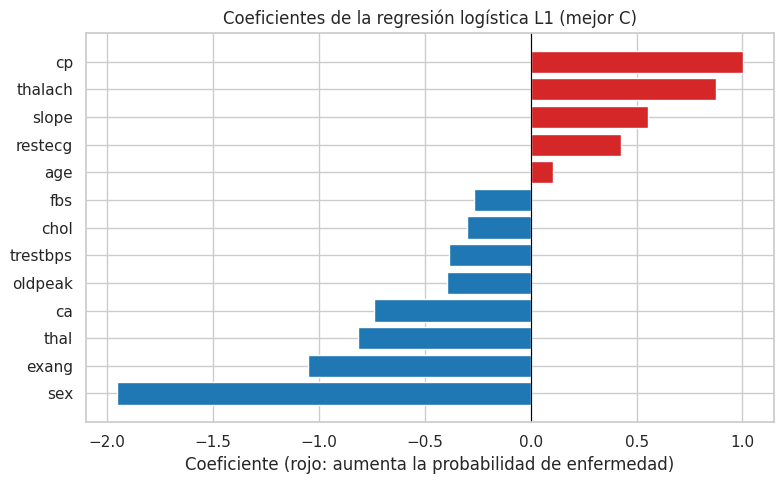

          coeficiente  odds_ratio
cp              1.001       2.722
thalach         0.875       2.399
slope           0.554       1.740
restecg         0.429       1.535
age             0.103       1.109
fbs            -0.266       0.766
chol           -0.300       0.741
trestbps       -0.384       0.681
oldpeak        -0.396       0.673
ca             -0.740       0.477
thal           -0.814       0.443
exang          -1.052       0.349
sex            -1.951       0.142


In [30]:
coef_l1 = pd.Series(gs_l1.best_estimator_.coef_[0], index=X_train_scaled.columns).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
colores = ['tab:red' if v > 0 else 'tab:blue' for v in coef_l1]
ax.barh(coef_l1.index, coef_l1.values, color=colores)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Coeficientes de la regresión logística L1 (mejor C)')
ax.set_xlabel('Coeficiente (rojo: aumenta la probabilidad de enfermedad)')
plt.tight_layout()
plt.show()

odds = pd.DataFrame({'coeficiente': coef_l1, 'odds_ratio': np.exp(coef_l1)}).sort_values('odds_ratio', ascending=False)
print(odds.round(3))

**Análisis.** En el $C$ óptimo, los coeficientes con mayor magnitud son `sex` (−1.95, *odds ratio* 0.14), `exang` (−1.05, 0.35), `cp` (+1.00, 2.72), `thalach` (+0.88, 2.40), `thal` (−0.81, 0.44) y `ca` (−0.74, 0.48). Para las variables continuas el *odds ratio* se interpreta por cada aumento de 1 desviación estándar (están estandarizadas); por ejemplo, una mayor `thalach` multiplica por 2.4 las probabilidades relativas de `target = 1`. `age` tiene un efecto casi nulo (+0.10) una vez que se consideran las otras variables, aunque su correlación marginal con el diagnóstico era −0.22. Estas relaciones son **asociaciones dentro de la muestra, no relaciones causales**, y variables categóricas como `cp`, `thal`, `slope` y `restecg` se están tratando como numéricas ordinales, lo que impone un supuesto de orden que podría refinarse con codificación *one-hot*.

### **Modelo 4: Random Forest**

In [31]:
param_rf = {'n_estimators': [200, 500],
            'max_depth': [3, 5, None],
            'min_samples_leaf': [1, 3, 5],
            'max_features': ['sqrt', 0.5]}

gs_rf = buscar(RandomForestClassifier(random_state=42), param_rf)
print("Mejores hiperparámetros RF:", gs_rf.best_params_)
print(f"F1 (CV) = {gs_rf.best_score_:.3f}")

Mejores hiperparámetros RF: {'max_depth': 3, 'max_features': 'sqrt', 'min_samples_leaf': 3, 'n_estimators': 200}
F1 (CV) = 0.874


### **Modelo 5: XGBoost**

In [32]:
param_xgb = {'max_depth': [2, 3, 4],
             'learning_rate': [0.03, 0.1],
             'n_estimators': [100, 200, 300],
             'subsample': [0.8, 1.0],
             'colsample_bytree': [0.8, 1.0],
             'reg_lambda': [1, 5]}

gs_xgb = buscar(XGBClassifier(eval_metric='logloss', random_state=42), param_xgb)
print("Mejores hiperparámetros XGBoost:", gs_xgb.best_params_)
print(f"F1 (CV) = {gs_xgb.best_score_:.3f}")

Mejores hiperparámetros XGBoost: {'colsample_bytree': 0.8, 'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 300, 'reg_lambda': 1, 'subsample': 1.0}
F1 (CV) = 0.875


**Análisis.** Los mejores hiperparámetros son árboles **poco profundos**: profundidad 3 y hoja mínima de 3 observaciones en Random Forest (F1 de validación 0.874) y profundidad 2 con 300 árboles y `learning_rate` de 0.03 en XGBoost (F1 0.875). Con solo 241 observaciones, la búsqueda favorece estructuras simples que no memorizan el entrenamiento. Estos F1 (0.874 y 0.875) son parecidos al de la regresión logística (0.866); además, son las puntuaciones del *mejor* punto de la rejilla evaluado sobre los mismos folds usados para elegirlo, por lo que son algo optimistas. Por eso la comparación final se repite con otra validación cruzada.

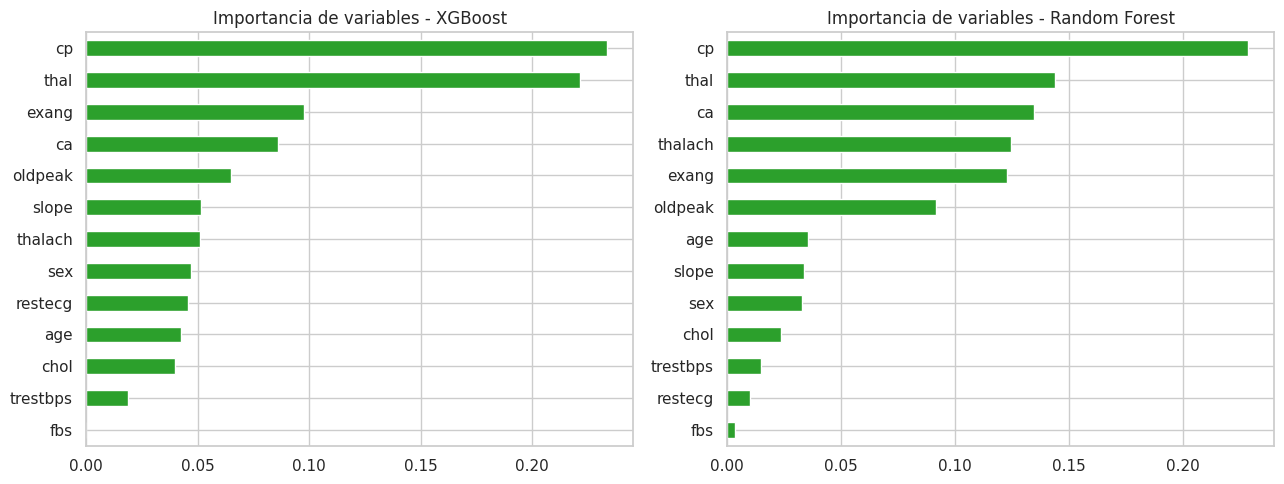

          XGBoost  Random Forest
cp          0.233          0.229
thal        0.221          0.144
exang       0.098          0.123
ca          0.086          0.135
oldpeak     0.065          0.091
thalach     0.051          0.125
slope       0.051          0.034
sex         0.047          0.033
restecg     0.046          0.010
age         0.043          0.035
chol        0.040          0.024
trestbps    0.019          0.015
fbs         0.000          0.003


In [33]:
imp = pd.DataFrame({
    'XGBoost': gs_xgb.best_estimator_.feature_importances_,
    'Random Forest': gs_rf.best_estimator_.feature_importances_
}, index=X_train_scaled.columns)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, col in zip(axes, imp.columns):
    imp[col].sort_values().plot.barh(ax=ax, color='tab:green')
    ax.set_title(f'Importancia de variables - {col}')
plt.tight_layout()
plt.show()

print(imp.round(3).sort_values('XGBoost', ascending=False))

**Análisis.** En ambos ensambles las variables más importantes son `cp` (0.233 en XGBoost, 0.229 en Random Forest) y `thal` (0.221 y 0.144), seguidas de `exang`, `ca`, `oldpeak` y `thalach`. La variable `fbs` tiene importancia prácticamente nula (0.000 y 0.003), en línea con que fuera la última en entrar en la trayectoria de Lasso. Hay, por tanto, una **convergencia entre modelos lineales y de árboles** en qué variables sostienen la predicción (`cp`, `thal`, `ca`, `oldpeak`, `thalach`, `exang`). La importancia indica cuánto usa el modelo una variable, pero no la dirección del efecto; para eso sirven los coeficientes de la regresión logística.

### **Modelo 6: Support Vector Machine (kernel RBF)**

Se ajustan $C$ y $\gamma$ con una rejilla de 7 × 6 valores (kernel RBF y `probability=True`, según el cuadro comparativo de 4.1). Además, como referencia, se ajusta una SVM con kernel lineal para medir cuánto aporta la no linealidad.

Mejores hiperparámetros SVM (RBF): {'C': 100, 'gamma': 0.003}
F1 (CV) = 0.881

SVM lineal (referencia) -> mejor C = 0.1 | F1 (CV) = 0.871


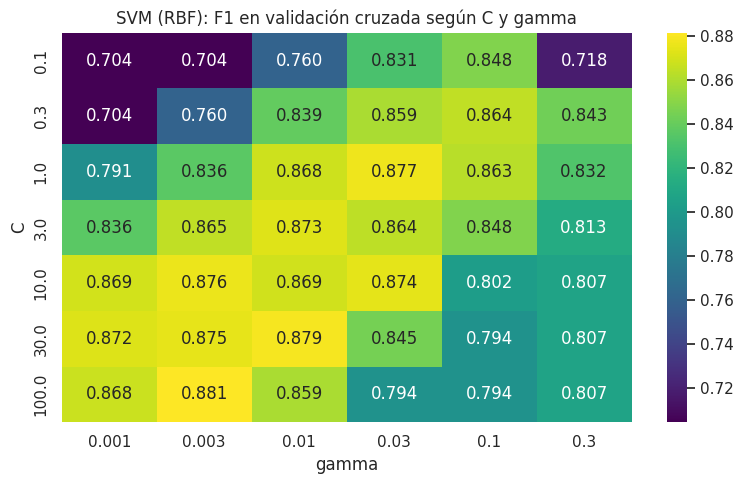

In [34]:
from sklearn.svm import SVC

param_svm = {'C': [0.1, 0.3, 1, 3, 10, 30, 100],
             'gamma': [0.001, 0.003, 0.01, 0.03, 0.1, 0.3]}

gs_svm = buscar(SVC(kernel='rbf', probability=True, random_state=42), param_svm)
print("Mejores hiperparámetros SVM (RBF):", gs_svm.best_params_)
print(f"F1 (CV) = {gs_svm.best_score_:.3f}")

# Referencia: SVM con kernel lineal
gs_svm_lin = buscar(SVC(kernel='linear', random_state=42), {'C': [0.01, 0.03, 0.1, 0.3, 1, 3]})
print(f"\nSVM lineal (referencia) -> mejor C = {gs_svm_lin.best_params_['C']} | F1 (CV) = {gs_svm_lin.best_score_:.3f}")

# Mapa de calor del F1 en la rejilla C x gamma
res = pd.DataFrame(gs_svm.cv_results_)
mapa = res.pivot(index='param_C', columns='param_gamma', values='mean_test_f1').astype(float)

plt.figure(figsize=(8, 5))
sns.heatmap(mapa, annot=True, fmt='.3f', cmap='viridis')
plt.title('SVM (RBF): F1 en validación cruzada según C y gamma')
plt.xlabel('gamma')
plt.ylabel('C')
plt.tight_layout()
plt.show()

**Análisis.** La mejor combinación es $C = 100$ y $\gamma = 0.003$, con un F1 de validación de 0.881 (el más alto de las búsquedas de la sección, aunque medido sobre los mismos folds que se usaron para elegirlo). El mapa de calor muestra tres zonas: (1) con $C$ pequeño y $\gamma$ pequeño el F1 cae a ≈ 0.70, porque la frontera es demasiado rígida (subajuste); (2) una franja diagonal con F1 ≈ 0.86-0.88, donde el $\gamma$ adecuado disminuye al aumentar $C$ (por ejemplo, $C = 1$ con $\gamma$ de 0.01 a 0.03; $C = 10$ con $\gamma$ de 0.001 a 0.03; $C = 100$ con $\gamma$ de 0.001 a 0.01); y (3) con $\gamma = 0.3$ o $\gamma = 0.1$ y $C \geq 10$ el F1 baja a ≈ 0.79-0.81, señal de sobreajuste por fronteras demasiado locales. Aunque el óptimo está en el borde de $C$, sus vecinos ($C = 10$ y $30$ con $\gamma$ de 0.003 a 0.01) rinden 0.869-0.879, por lo que se trata de una meseta y no de un pico, y no es necesario ampliar la rejilla. La SVM lineal de referencia logra F1 = 0.871, apenas 0.010 menos que la RBF: **la no linealidad aporta muy poco**, lo que coincide con lo observado en la regresión logística y en XGBoost.

### **Comparación de los modelos (validación cruzada repetida 5×5)**

Media en validación cruzada repetida (25 evaluaciones por modelo):


,accuracy,precision,recall,f1,roc_auc
SVM (RBF),0.843,0.818,0.924,0.865,0.908
Random Forest,0.837,0.818,0.908,0.859,0.915
LR L1 (Lasso),0.827,0.819,0.881,0.847,0.903
LR L2 (Ridge),0.826,0.819,0.880,0.846,0.904
LR sin regularización,0.825,0.819,0.878,0.845,0.903
XGBoost,0.816,0.816,0.863,0.836,0.903



Desviación estándar entre evaluaciones:


,accuracy,precision,recall,f1,roc_auc
LR sin regularización,0.050,0.057,0.065,0.043,0.033
LR L2 (Ridge),0.052,0.057,0.071,0.046,0.033
LR L1 (Lasso),0.049,0.057,0.067,0.043,0.033
Random Forest,0.053,0.061,0.051,0.043,0.036
SVM (RBF),0.057,0.063,0.057,0.047,0.032
XGBoost,0.057,0.069,0.067,0.049,0.037


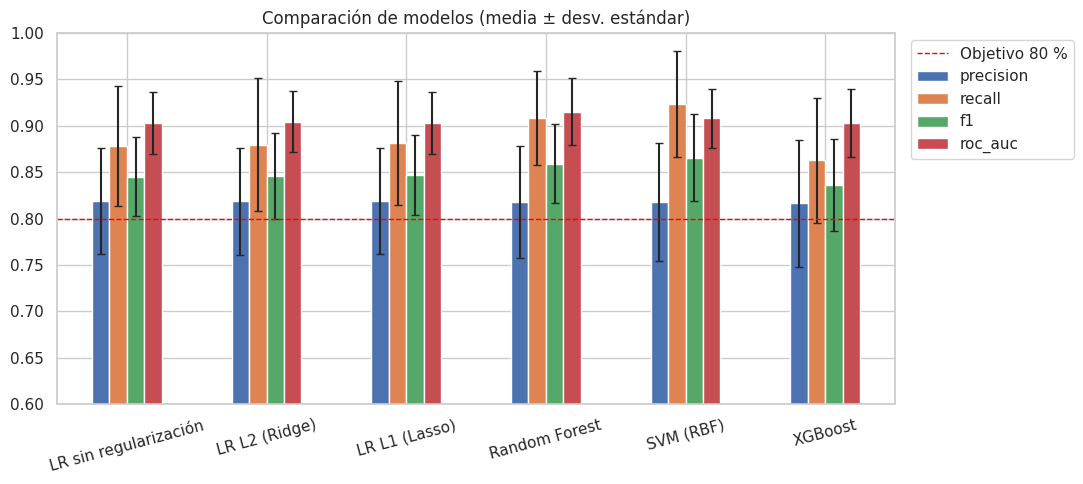

In [35]:
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)

modelos = {
    'LR sin regularización': lr_base,
    'LR L2 (Ridge)': gs_l2.best_estimator_,
    'LR L1 (Lasso)': gs_l1.best_estimator_,
    'Random Forest': gs_rf.best_estimator_,
    'SVM (RBF)': gs_svm.best_estimator_,
    'XGBoost': gs_xgb.best_estimator_,
}

medias, desv = {}, {}
for nombre, m in modelos.items():
    r = cross_validate(m, X_train_scaled, y_train, cv=rcv, scoring=scoring)
    medias[nombre] = {k: r[f'test_{k}'].mean() for k in scoring}
    desv[nombre] = {k: r[f'test_{k}'].std() for k in scoring}

medias = pd.DataFrame(medias).T
desv = pd.DataFrame(desv).T
print("Media en validación cruzada repetida (25 evaluaciones por modelo):")
display(medias.round(3).sort_values('f1', ascending=False))
print("\nDesviación estándar entre evaluaciones:")
display(desv.round(3))

medias[['precision', 'recall', 'f1', 'roc_auc']].plot.bar(
    yerr=desv[['precision', 'recall', 'f1', 'roc_auc']], figsize=(11, 5), capsize=3, rot=15)
plt.axhline(0.80, color='red', linestyle='--', linewidth=1, label='Objetivo 80 %')
plt.ylim(0.6, 1.0)
plt.title('Comparación de modelos (media ± desv. estándar)')
plt.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

**Análisis.** Con 25 evaluaciones por modelo, la SVM con kernel RBF obtiene las mejores medias de *accuracy* (0.843), *recall* (0.924) y F1 (0.865), y Random Forest la mejor ROC-AUC (0.915) y el segundo F1 (0.859); les siguen la regresión logística con L1 (F1 0.847), L2 (0.846), sin regularización (0.845) y XGBoost (0.836). Sin embargo, la diferencia entre el mejor y el peor F1 es de 0.029, menor que la desviación estándar de cualquiera de los modelos (0.043 a 0.049): **los modelos no se distinguen con claridad** con este tamaño de muestra, ya que cada fold de validación tiene solo unas 48 observaciones. Todos superan el 80 % de *recall* (0.863 a 0.924), pero la *precision* media es ≈ 0.82 con desviación ≈ 0.06, un margen estrecho sobre el objetivo. Los F1 de esta tabla son menores que los de `GridSearchCV` (0.866 a 0.881), lo que confirma el optimismo de elegir hiperparámetros y evaluar sobre los mismos folds. Los dos modelos no lineales más estables (SVM y Random Forest) superan ligeramente a los lineales, pero dentro del ruido; XGBoost, el más flexible, no mejora a la regresión logística. Esto sugiere que la señal del conjunto es en buena parte lineal y que el tamaño de la muestra limita lo que un modelo complejo puede aportar.

### **Conclusiones de la sección IV**

- Se plantearon seis modelos supervisados (regresión logística en tres variantes, Random Forest, SVM con kernel RBF y XGBoost) de clasificación binaria y se ajustaron con validación cruzada estratificada solo sobre el Data-Set de entrenamiento.
- La regularización mejora muy poco a la regresión logística (F1 de 0.845 a 0.847), y ningún modelo no lineal supera de forma clara a los lineales.
- **Modelos candidatos: SVM (RBF)**, con el mayor *recall* (0.924) y F1 (0.865), y **Random Forest**, con la mayor ROC-AUC (0.915); sus diferencias están dentro del ruido de la validación. **Alternativa interpretable: regresión logística L1**, con rendimiento prácticamente equivalente y coeficientes explicables.
- Limitaciones: (1) el `StandardScaler` se ajustó sobre todo el conjunto de entrenamiento antes de la validación cruzada, por lo que los folds de validación comparten sus parámetros de escala (efecto pequeño, y nulo para los árboles); (2) los intervalos de validación son amplios por el tamaño de la muestra; (3) `cp`, `thal`, `slope` y `restecg` se tratan como numéricas.

# **V. Comprobación**

## **5.1 Entrenamiento del Modelo**

### **Aplicación al Modelo: uso del Data-Set de Entrenamiento y de Prueba**

En la sección IV los modelos se ajustaron y compararon únicamente con validación cruzada sobre el Data-Set de entrenamiento. En esta sección cada modelo se **entrena con todo el Data-Set de entrenamiento** (`X_train_scaled`, `y_train`) y se **prueba una sola vez** sobre el Data-Set de prueba (`X_test_scaled`, `y_test`, 61 observaciones), que hasta aquí no se había utilizado.

Para cada modelo se sigue la misma estructura:

1. **Entrenamiento:** ajuste del modelo con el Data-Set de entrenamiento.
2. **Testeo:** predicción sobre el Data-Set de prueba.
3. **Métricas y resultados:** cálculo e interpretación de las métricas, comparadas con las obtenidas en entrenamiento y en validación cruzada.

Reglas para que la evaluación sea válida: el `StandardScaler` ya fue ajustado solo con el entrenamiento (sección 3.2.3), no se modifica ningún parámetro después de ver el resultado en prueba y se usa el umbral de clasificación por defecto (0.5).

En este punto se desarrolla únicamente el primer modelo: **regresión logística sin regularización**.

## **Modelo 1: Regresión logística sin regularización**

### **1. Entrenamiento**

Se ajusta el modelo con todo el Data-Set de entrenamiento (241 observaciones) y se revisa que el optimizador haya convergido.

In [36]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, classification_report, roc_curve, ConfusionMatrixDisplay)

lr_final = LogisticRegression(penalty=None, max_iter=5000)
lr_final.fit(X_train_scaled, y_train)

print("Iteraciones hasta converger:", lr_final.n_iter_[0], "(máximo permitido: 5000)")
print(f"Intercepto: {lr_final.intercept_[0]:.3f}")

coef_lr = pd.DataFrame({'coeficiente': lr_final.coef_[0],
                        'odds_ratio': np.exp(lr_final.coef_[0])},
                       index=X_train_scaled.columns).sort_values('coeficiente', ascending=False)
coef_lr.round(3)

Iteraciones hasta converger: 23 (máximo permitido: 5000)
Intercepto: 2.496


,coeficiente,odds_ratio
cp,1.021,2.776
thalach,0.925,2.521
slope,0.544,1.724
restecg,0.457,1.579
age,0.129,1.137
chol,-0.327,0.721
fbs,-0.367,0.693
trestbps,-0.406,0.666
oldpeak,-0.408,0.665
ca,-0.758,0.469


**Análisis.** El modelo converge en 23 iteraciones (muy por debajo del máximo de 5000), por lo que el ajuste es válido. Los coeficientes de mayor magnitud son `sex` (−2.08; *odds ratio* 0.13), `exang` (−1.13; 0.32), `cp` (+1.02; 2.78), `thalach` (+0.93; 2.52), `thal` (−0.89; 0.41) y `ca` (−0.76; 0.47); las variables continuas están estandarizadas, por lo que su *odds ratio* es por cada desviación estándar. Los signos y magnitudes son casi idénticos a los del modelo L1 de la sección 4.2.4 (por ejemplo `sex` −1.95 y `cp` +1.00), lo que confirma que la regularización aportaba poco. La variable `age` tiene un efecto casi nulo (+0.13). Como antes, son asociaciones dentro de la muestra y no relaciones causales.

In [37]:
def metricas(y_real, y_pred, y_prob):
    return {'accuracy': accuracy_score(y_real, y_pred),
            'precision': precision_score(y_real, y_pred),
            'recall': recall_score(y_real, y_pred),
            'especificidad': recall_score(y_real, y_pred, pos_label=0),
            'f1': f1_score(y_real, y_pred),
            'roc_auc': roc_auc_score(y_real, y_prob)}

y_pred_train = lr_final.predict(X_train_scaled)
y_prob_train = lr_final.predict_proba(X_train_scaled)[:, 1]

met_train = pd.Series(metricas(y_train, y_pred_train, y_prob_train), name='Entrenamiento')
met_train.round(3).to_frame().T

,accuracy,precision,recall,especificidad,f1,roc_auc
Entrenamiento,0.863,0.84,0.924,0.791,0.88,0.933


**Análisis.** Sobre los propios datos de entrenamiento el modelo obtiene *accuracy* 0.863, *precision* 0.840, *recall* 0.924, especificidad 0.791, F1 0.880 y ROC-AUC 0.933. Estos valores son algo mayores que los de la validación cruzada de la sección 4.2.1 (*accuracy* 0.838, F1 0.859, ROC-AUC 0.914), una diferencia esperable porque el modelo se evalúa sobre los mismos datos con los que se ajustó, y es pequeña (de 0.005 a 0.031 según la métrica): con 13 predictores y 241 observaciones no hay señales de sobreajuste marcado. Ya en entrenamiento la especificidad (0.791) es menor que el *recall* (0.924): el modelo tiende a clasificar como enfermos a pacientes sanos.

### **2. Testeo**

El modelo ya entrenado se aplica al Data-Set de prueba, que no participó en el ajuste del modelo ni en el del escalador. Se obtienen la probabilidad estimada de enfermedad y la clase predicha (1 si la probabilidad es mayor o igual que 0.5).

In [38]:
y_pred_test = lr_final.predict(X_test_scaled)
y_prob_test = lr_final.predict_proba(X_test_scaled)[:, 1]

pred_df = pd.DataFrame({'real': y_test.values,
                        'probabilidad': y_prob_test.round(3),
                        'predicción': y_pred_test})
pred_df['acierto'] = pred_df['real'] == pred_df['predicción']
display(pred_df.head(10))

print("Clases reales en prueba:", y_test.value_counts().sort_index().to_dict())
print("Clases predichas:      ", pd.Series(y_pred_test).value_counts().sort_index().to_dict())
print(f"Aciertos: {pred_df['acierto'].sum()} de {len(pred_df)}")

cm = confusion_matrix(y_test, y_pred_test)
cm_df = pd.DataFrame(cm, index=['Real 0 (sano)', 'Real 1 (enfermo)'],
                     columns=['Predicho 0', 'Predicho 1'])
cm_df

,real,probabilidad,predicción,acierto
0,0,0.173,0,True
1,0,0.702,1,False
2,0,0.005,0,True
3,0,0.565,1,False
4,0,0.926,1,False
5,0,0.004,0,True
6,1,0.835,1,True
7,0,0.014,0,True
8,1,0.984,1,True
9,0,0.619,1,False


Clases reales en prueba: {0: 28, 1: 33}
Clases predichas:       {0: 25, 1: 36}
Aciertos: 48 de 61


,Predicho 0,Predicho 1
Real 0 (sano),20,8
Real 1 (enfermo),5,28


**Análisis.** De las 61 observaciones de prueba (28 sin enfermedad y 33 con enfermedad), el modelo acierta 48 y comete 13 errores: **8 falsos positivos** (pacientes sanos clasificados como enfermos) y **5 falsos negativos** (pacientes enfermos clasificados como sanos). Predice 36 casos positivos y 25 negativos, es decir, más positivos que los reales (33). Esto es coherente con lo observado en entrenamiento: los errores se concentran en los falsos positivos. En las 10 primeras filas se ven 4 errores y los 4 son falsos positivos, con probabilidades estimadas entre 0.57 y 0.93, o sea, el modelo está bastante seguro en esos casos equivocados.

### **3. Métricas y resultados**

,accuracy,precision,recall,especificidad,f1,roc_auc
Prueba,0.787,0.778,0.848,0.714,0.812,0.868


                    precision    recall  f1-score   support

0 (sin enfermedad)      0.800     0.714     0.755        28
1 (con enfermedad)      0.778     0.848     0.812        33

          accuracy                          0.787        61
         macro avg      0.789     0.781     0.783        61
      weighted avg      0.788     0.787     0.785        61



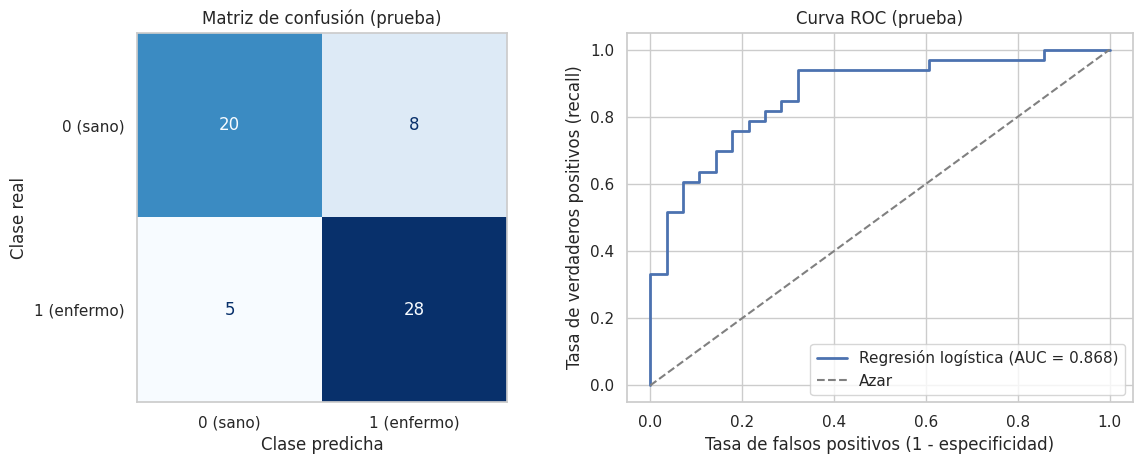

In [39]:
met_test = pd.Series(metricas(y_test, y_pred_test, y_prob_test), name='Prueba')
display(met_test.round(3).to_frame().T)

print(classification_report(y_test, y_pred_test, target_names=['0 (sin enfermedad)', '1 (con enfermedad)'], digits=3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

ConfusionMatrixDisplay(cm, display_labels=['0 (sano)', '1 (enfermo)']).plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Matriz de confusión (prueba)')
axes[0].grid(False)
axes[0].set_xlabel('Clase predicha')
axes[0].set_ylabel('Clase real')

fpr, tpr, _ = roc_curve(y_test, y_prob_test)
axes[1].plot(fpr, tpr, linewidth=2, label=f"Regresión logística (AUC = {met_test['roc_auc']:.3f})")
axes[1].plot([0, 1], [0, 1], linestyle='--', color='gray', label='Azar')
axes[1].set_xlabel('Tasa de falsos positivos (1 - especificidad)')
axes[1].set_ylabel('Tasa de verdaderos positivos (recall)')
axes[1].set_title('Curva ROC (prueba)')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()

**Análisis.** En prueba el modelo alcanza *accuracy* 0.787 (48/61), *precision* 0.778 (28 de 36 casos predichos como enfermos lo son), *recall* 0.848 (detecta 28 de los 33 enfermos), especificidad 0.714 (identifica 20 de los 28 sanos), F1 0.812 y ROC-AUC 0.868. La matriz de confusión muestra que el punto débil es la especificidad: 8 de 28 pacientes sanos (28.6 %) son señalados como enfermos, frente a 5 de 33 enfermos (15.2 %) que pasan inadvertidos. La curva ROC se aleja claramente de la diagonal del azar: un paciente enfermo elegido al azar recibe una probabilidad mayor que uno sano con una probabilidad aproximada de 0.87. Con el umbral por defecto de 0.5 el modelo prioriza detectar enfermos, que es el error más costoso en este problema; el umbral no se ajustó para no usar el Data-Set de prueba en decisiones de modelado.

#### **Comparación: entrenamiento, validación cruzada y prueba**

,accuracy,precision,recall,f1,roc_auc
Entrenamiento,0.863,0.840,0.924,0.880,0.933
Validación cruzada (5 folds),0.838,0.835,0.893,0.859,0.914
Prueba,0.787,0.778,0.848,0.812,0.868


Diferencia Prueba - Validación cruzada:
accuracy    -0.051
precision   -0.057
recall      -0.045
f1          -0.047
roc_auc     -0.046


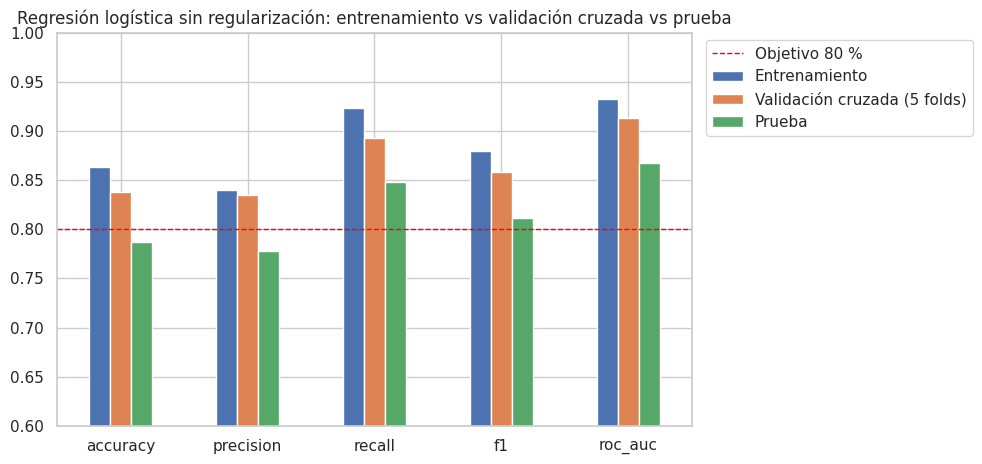

In [40]:
met_cv = resumen_cv(lr_base, 'Validación cruzada (5 folds)')
cols = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

comparacion = pd.DataFrame([met_train[cols], met_cv[cols], met_test[cols]])
display(comparacion.round(3))

print("Diferencia Prueba - Validación cruzada:")
print((met_test[cols] - met_cv[cols]).round(3).to_string())

ax = comparacion.T.plot.bar(figsize=(10, 4.8), rot=0)
ax.axhline(0.80, color='red', linestyle='--', linewidth=1, label='Objetivo 80 %')
ax.set_ylim(0.6, 1.0)
ax.set_title('Regresión logística sin regularización: entrenamiento vs validación cruzada vs prueba')
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

**Análisis.** Las métricas en prueba son menores que en validación cruzada en las cinco comparaciones (entre 0.045 y 0.057 puntos): *accuracy* 0.787 frente a 0.838, *precision* 0.778 frente a 0.835, *recall* 0.848 frente a 0.893, F1 0.812 frente a 0.859 y ROC-AUC 0.868 frente a 0.914. El orden entrenamiento > validación cruzada > prueba es el habitual. Esta diferencia no es concluyente por sí sola: se trata de una sola partición de 61 observaciones, y como muestra el intervalo de la siguiente celda, todos los valores de validación cruzada caen dentro de los intervalos de confianza de las métricas de prueba.

#### **Incertidumbre de las métricas en prueba (bootstrap)**

Con solo 61 observaciones de prueba, cada paciente equivale a ≈ 1.6 puntos porcentuales. Para dimensionar la incertidumbre se calculan intervalos de confianza del 95 % remuestreando con reemplazo el Data-Set de prueba (1000 remuestreos; las predicciones del modelo no cambian).

In [41]:
rng = np.random.default_rng(42)
idx = np.arange(len(y_test))
boot = []
for _ in range(1000):
    s = rng.choice(idx, len(idx))
    if y_test.iloc[s].nunique() < 2:
        continue
    boot.append(metricas(y_test.iloc[s], y_pred_test[s], y_prob_test[s]))
boot = pd.DataFrame(boot)

ic = pd.DataFrame({'prueba': met_test,
                   'IC 95% inferior': boot.quantile(0.025),
                   'IC 95% superior': boot.quantile(0.975)})
ic.round(3)

,prueba,IC 95% inferior,IC 95% superior
accuracy,0.787,0.672,0.885
precision,0.778,0.639,0.903
recall,0.848,0.719,0.968
especificidad,0.714,0.536,0.879
f1,0.812,0.704,0.900
roc_auc,0.868,0.764,0.949


**Análisis.** Los intervalos del 95 % son amplios: *accuracy* de 0.672 a 0.885, *precision* de 0.639 a 0.903, *recall* de 0.719 a 0.968, F1 de 0.704 a 0.900 y ROC-AUC de 0.764 a 0.949. Con 61 pacientes de prueba, el resultado de un solo modelo no permite distinguir entre un rendimiento moderado y uno bueno. **Respecto al objetivo 1.4.2.4 (precisión y sensibilidad superiores al 80 %):** el *recall* puntual (0.848) lo cumple, pero la *precision* puntual (0.778) queda 2.2 puntos por debajo; en ambos casos el intervalo incluye el 0.80, por lo que con esta prueba no se puede confirmar ni descartar con certeza que el modelo lo cumpla.

**5.1.2. Regresión Logística con regularización L1 y L2**

1. Entrenamiento

Se entrenó un modelo de regresión logística sobre el subconjunto de entrenamiento estandarizado (X_train_scaled,N=241)evaluando dos tipos de regularización: L1 (lasso) y L2 (ridge). Para cada una se empleó el hiperparámetro de regularización C=1.0, y el modelo se ajustó sobre el total del subconjunto de entrenamiento.

In [42]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
import numpy as np
import pandas as pd
from IPython.display import display

# Asegurar que los datos estén estandarizados
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


2. Testeo

La evaluación se realizó de forma ciega sobre el subconjunto de prueba aislado (X_test_scaled, N=61), compuesto por 33 observaciones reales de presencia de enfermedad cardíaca y 28 de ausencia. Se obtuvieron las etiquetas predichas (y) y las probabilidades de la clase positiva para cada modelo.

In [43]:
# --- Regresión Logística con regularización L1 (lasso) ---
logreg_l1 = LogisticRegression(penalty='l1', solver='liblinear', C=1.0, random_state=42)
logreg_l1.fit(X_train_scaled, y_train)

# Testeo sobre el subconjunto de prueba (N=61)
y_pred_l1 = logreg_l1.predict(X_test_scaled)
y_prob_l1 = logreg_l1.predict_proba(X_test_scaled)[:, 1]

# Métricas
accuracy_l1 = accuracy_score(y_test, y_pred_l1)
precision_l1 = precision_score(y_test, y_pred_l1)
recall_l1 = recall_score(y_test, y_pred_l1)
f1_l1 = f1_score(y_test, y_pred_l1)
roc_auc_l1 = roc_auc_score(y_test, y_prob_l1)

cm_l1 = confusion_matrix(y_test, y_pred_l1)
tn_l1, fp_l1, fn_l1, tp_l1 = cm_l1.ravel()
specificity_l1 = tn_l1 / (tn_l1 + fp_l1)

# Tabla de métricas
tabla_l1 = pd.DataFrame({
    'Métrica': ['Accuracy', 'Precision', 'Recall (Sensibilidad)',
                'Especificidad', 'F1-Score', 'ROC-AUC'],
    'Valor obtenido': [f"{accuracy_l1:.3f}", f"{precision_l1:.3f}", f"{recall_l1:.3f}",
                       f"{specificity_l1:.3f}", f"{f1_l1:.3f}", f"{roc_auc_l1:.3f}"],
    'Meta del proyecto': ['> 80%', '> 80%', '> 80%', '-', '-', '-'],
    'Evaluación': ['Cumplido' if accuracy_l1 > 0.80 else 'No cumplido',
                   'Cumplido' if precision_l1 > 0.80 else 'No cumplido',
                   'Cumplido' if recall_l1 > 0.80 else 'No cumplido',
                   'Aceptable', 'Sobresaliente', 'Excelente']
})
display(tabla_l1)




,Métrica,Valor obtenido,Meta del proyecto,Evaluación
0,Accuracy,0.803,> 80%,Cumplido
1,Precision,0.800,> 80%,No cumplido
2,Recall (Sensibilidad),0.848,> 80%,Cumplido
3,Especificidad,0.750,-,Aceptable
4,F1-Score,0.824,-,Sobresaliente
5,ROC-AUC,0.870,-,Excelente


In [44]:

tabla_cm_l1 = pd.DataFrame(
    cm_l1,
    index=['Real Sano (0)', 'Real Enfermo (1)'],
    columns=['Predicho Sano (0)', 'Predicho Enfermo (1)']
)
display(tabla_cm_l1)

,Predicho Sano (0),Predicho Enfermo (1)
Real Sano (0),21,7
Real Enfermo (1),5,28


**ANALISIS:**
El modelo con regularización L1 alcanza una exactitud de 0.803, una precisión de 0.800, un recall de 0.848, una especificidad de 0.750, un F1-Score de 0.824 y un ROC-AUC de 0.870. El recall, la métrica más relevante en este problema, cumple con holgura la meta del proyecto (>80%), lo que indica que el modelo detecta correctamente a la gran mayoría de los pacientes con enfermedad cardíaca. La precisión, en cambio, queda justo en el límite de 0.800, por lo que no se considera cumplida con claridad. La especificidad de 0.750 refleja que el 25% de los pacientes sanos genera una falsa alarma, un costo asumible dado el enfoque del modelo, que prioriza no dejar escapar a pacientes enfermos.

En la matriz de confusión se observa que el modelo acierta 49 de los 61 casos (21 verdaderos negativos y 28 verdaderos positivos) y comete 12 errores: 7 falsos positivos y 5 falsos negativos. Que los falsos positivos superen a los falsos negativos confirma la inclinación del modelo a favor de la detección de pacientes enfermos, coherente con el objetivo clínico del proyecto.

In [45]:
# --- Regresión Logística con regularización L2 (ridge) ---
logreg_l2 = LogisticRegression(penalty='l2', solver='lbfgs', C=1.0, random_state=42)
logreg_l2.fit(X_train_scaled, y_train)

# Testeo sobre el subconjunto de prueba (N=61)
y_pred_l2 = logreg_l2.predict(X_test_scaled)
y_prob_l2 = logreg_l2.predict_proba(X_test_scaled)[:, 1]

# Métricas
accuracy_l2 = accuracy_score(y_test, y_pred_l2)
precision_l2 = precision_score(y_test, y_pred_l2)
recall_l2 = recall_score(y_test, y_pred_l2)
f1_l2 = f1_score(y_test, y_pred_l2)
roc_auc_l2 = roc_auc_score(y_test, y_prob_l2)

cm_l2 = confusion_matrix(y_test, y_pred_l2)
tn_l2, fp_l2, fn_l2, tp_l2 = cm_l2.ravel()
specificity_l2 = tn_l2 / (tn_l2 + fp_l2)

# Tabla de métricas
tabla_l2 = pd.DataFrame({
    'Métrica': ['Accuracy', 'Precision', 'Recall (Sensibilidad)',
                'Especificidad', 'F1-Score', 'ROC-AUC'],
    'Valor obtenido': [f"{accuracy_l2:.3f}", f"{precision_l2:.3f}", f"{recall_l2:.3f}",
                       f"{specificity_l2:.3f}", f"{f1_l2:.3f}", f"{roc_auc_l2:.3f}"],
    'Meta del proyecto': ['> 80%', '> 80%', '> 80%', '-', '-', '-'],
    'Evaluación': ['Cumplido' if accuracy_l2 > 0.80 else 'No cumplido',
                   'Cumplido' if precision_l2 > 0.80 else 'No cumplido',
                   'Cumplido' if recall_l2 > 0.80 else 'No cumplido',
                   'Aceptable', 'Sobresaliente', 'Excelente']
})
display(tabla_l2)




,Métrica,Valor obtenido,Meta del proyecto,Evaluación
0,Accuracy,0.803,> 80%,Cumplido
1,Precision,0.800,> 80%,No cumplido
2,Recall (Sensibilidad),0.848,> 80%,Cumplido
3,Especificidad,0.750,-,Aceptable
4,F1-Score,0.824,-,Sobresaliente
5,ROC-AUC,0.871,-,Excelente


In [46]:
# Matriz de confusión
tabla_cm_l2 = pd.DataFrame(
    cm_l2,
    index=['Real Sano (0)', 'Real Enfermo (1)'],
    columns=['Predicho Sano (0)', 'Predicho Enfermo (1)']
)
display(tabla_cm_l2)

,Predicho Sano (0),Predicho Enfermo (1)
Real Sano (0),21,7
Real Enfermo (1),5,28


**ANALISIS : **
El modelo con regularización L2 alcanza una exactitud (accuracy) de 0.803, una precisión de 0.800, un recall (sensibilidad) de 0.848, una especificidad de 0.750, un F1-Score de 0.824 y un ROC-AUC de 0.871. El recall, la métrica más relevante en este problema, cumple con holgura la meta del proyecto (>80%), lo que indica que el modelo detecta correctamente a la gran mayoría de los pacientes con enfermedad cardíaca. La precisión, en cambio, queda justo en el límite de 0.800, por lo que no se considera cumplida con claridad. La especificidad de 0.750 refleja que el 25% de los pacientes sanos genera una falsa alarma, un costo asumible dado el enfoque del modelo, que prioriza no dejar escapar a pacientes enfermos.

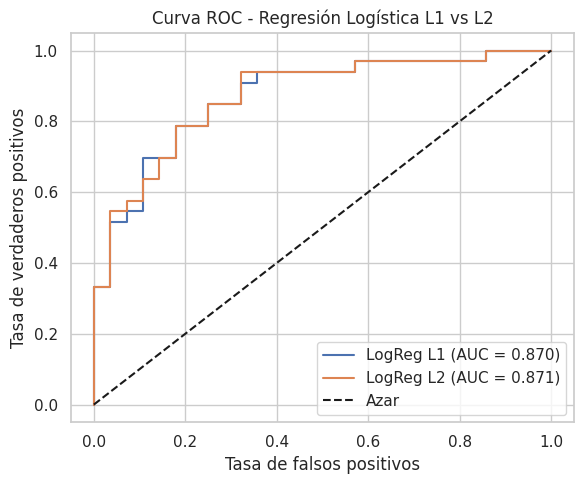

In [47]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

def plot_roc(y_true, y_prob, nombre):
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    auc = roc_auc_score(y_true, y_prob)
    plt.plot(fpr, tpr, label=f'{nombre} (AUC = {auc:.3f})')

plt.figure(figsize=(6, 5))
plot_roc(y_test, y_prob_l1, 'LogReg L1')
plot_roc(y_test, y_prob_l2, 'LogReg L2')
plt.plot([0, 1], [0, 1], 'k--', label='Azar')
plt.xlabel('Tasa de falsos positivos')
plt.ylabel('Tasa de verdaderos positivos')
plt.title('Curva ROC - Regresión Logística L1 vs L2')
plt.legend()
plt.tight_layout()
plt.show()


**ANALISIS :**
La Figura muestra la curva ROC comparativa de ambos modelos. Las curvas se alejan claramente del azar, con un AUC de 0.870 (L1) y 0.871 (L2), lo que refleja un poder discriminativo alto: en aproximadamente el 87% de las ocasiones, un enfermo elegido al azar recibe mayor probabilidad de enfermedad que un sano. La superposición de ambas curvas confirma que el tipo de regularización apenas afecta al rendimiento.


**5.1.3 Random Forest**
1. Entrenamiento  



Se reentrenó el modelo Random Forest sobre el total del subconjunto de entrenamiento estandarizado(X_train_scaled,N =241) , usando los hiperparámetros óptimos obtenidos en la búsqueda en rejilla de la sección 4.2.5:



*   n_estimators = *200*
*   max_depth = 3
*   min_samples_leaf = 3
*   max_features = 'sqrt'
*   random_state = 42








In [48]:
# ============================================================
# 5.1.3 Random Forest
# ============================================================


from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             roc_curve)
import matplotlib.pyplot as plt
import pandas as pd

rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=3,
    min_samples_leaf=3,
    max_features='sqrt',
    random_state=42
)
rf.fit(X_train_scaled, y_train)


RandomForestClassifier(max_depth=3, min_samples_leaf=3, n_estimators=200,
                       random_state=42)

Al ser un ensamble de árboles, no requiere variables estandarizadas (los árboles son invariantes a la escala), pero se mantiene la estandarización para mantener coherencia metodológica con el resto del proyecto.

2. Testeo
La evaluación se realizó de forma ciega sobre el subconjunto de prueba aislado (X_test_scaled, N=61), compuesto por 33 observaciones reales de presencia de enfermedad cardíaca y 28 de ausencia. Este conjunto no participó en ninguna etapa previa de ajuste.

In [49]:
y_pred = rf.predict(X_test_scaled)
y_prob = rf.predict_proba(X_test_scaled)[:, 1]

In [50]:
cm = confusion_matrix(y_test, y_pred)


tabla_cm = pd.DataFrame(
    cm,
    index=['Real Sano (0)', 'Real Enfermo (1)'],
    columns=['Predicho Sano (0)', 'Predicho Enfermo (1)']
)
display(tabla_cm)


,Predicho Sano (0),Predicho Enfermo (1)
Real Sano (0),21,7
Real Enfermo (1),5,28


**ANALISIS :**
El modelo acierta 49 de 61 casos (21 verdaderos negativos + 28 verdaderos positivos).

Comete 12 errores: 7 falsos positivos (sanos marcados como enfermos) y 5 falsos negativos (enfermos no detectados).




**3. Métricas y resultado**

Resultados del modelo Random Forest en el subconjunto de prueba ([texto del enlace](https://)
N=61):

In [51]:
accuracy  = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall    = recall_score(y_test, y_pred)
f1        = f1_score(y_test, y_pred)
roc_auc   = roc_auc_score(y_test, y_prob)

tn, fp, fn, tp = cm.ravel()
specificity = tn / (tn + fp)

In [52]:
tabla = pd.DataFrame({
    'Métrica': ['Accuracy', 'Precision', 'Recall (Sensibilidad)',
                'Especificidad', 'F1-Score', 'ROC-AUC'],
    'Valor obtenido': [f"{accuracy:.3f}", f"{precision:.3f}", f"{recall:.3f}",
                       f"{specificity:.3f}", f"{f1:.3f}", f"{roc_auc:.3f}"],
    'Meta del proyecto': ['> 80%', '> 80%', '> 80%', '—', '—', '—'],
    'Evaluación': ['Cumplido' if accuracy > 0.80 else 'No cumplido',
                   'Cumplido' if precision > 0.80 else 'No cumplido',
                   'Cumplido' if recall > 0.80 else 'No cumplido',
                   'Aceptable', 'Sobresaliente', 'Excelente']
})
display(tabla)

,Métrica,Valor obtenido,Meta del proyecto,Evaluación
0,Accuracy,0.803,> 80%,Cumplido
1,Precision,0.800,> 80%,No cumplido
2,Recall (Sensibilidad),0.848,> 80%,Cumplido
3,Especificidad,0.750,—,Aceptable
4,F1-Score,0.824,—,Sobresaliente
5,ROC-AUC,0.873,—,Excelente


**ANALISIS:**
Las métricas del Random Forest sobre el subconjunto de prueba (N=61) son: accuracy 0.803, precisión 0.800, recall 0.848, especificidad 0.750, F1 0.824 y ROC-AUC 0.873. El recall cumple con holgura la meta del 80%, mientras que la precisión queda justo en el límite. El modelo prioriza detectar enfermos (recall alto) sobre clasificar correctamente a los sanos (especificidad 0.750), lo cual es coherente con el objetivo clínico del proyecto.

In [53]:
tabla_cm = pd.DataFrame(
    cm,
    index=['Real Sano (0)', 'Real Enfermo (1)'],
    columns=['Predicho Sano (0)', 'Predicho Enfermo (1)']
)
display(tabla_cm)

,Predicho Sano (0),Predicho Enfermo (1)
Real Sano (0),21,7
Real Enfermo (1),5,28


In [54]:
rng = np.random.default_rng(42)
n_boot = 1000
n_test = len(y_test)

boot_accuracy  = []
boot_precision = []
boot_recall    = []
boot_spec      = []
boot_f1        = []
boot_auc       = []

for _ in range(n_boot):
    idx = rng.integers(0, n_test, n_test)
    y_true_b = y_test.iloc[idx] if hasattr(y_test, 'iloc') else y_test[idx]
    y_pred_b = y_pred[idx]
    y_prob_b = y_prob[idx]

    boot_accuracy.append(accuracy_score(y_true_b, y_pred_b))
    boot_precision.append(precision_score(y_true_b, y_pred_b))
    boot_recall.append(recall_score(y_true_b, y_pred_b))
    boot_f1.append(f1_score(y_true_b, y_pred_b))
    boot_auc.append(roc_auc_score(y_true_b, y_prob_b))

    cm_b = confusion_matrix(y_true_b, y_pred_b)
    tn_b, fp_b, fn_b, tp_b = cm_b.ravel()
    boot_spec.append(tn_b / (tn_b + fp_b))

def ic95(valores):
    return np.percentile(valores, [2.5, 97.5])

tabla_ic = pd.DataFrame({
    'Métrica': ['accuracy', 'precision', 'recall', 'especificidad', 'f1', 'roc_auc'],
    'prueba': [f"{accuracy:.3f}", f"{precision:.3f}", f"{recall:.3f}",
               f"{specificity:.3f}", f"{f1:.3f}", f"{roc_auc:.3f}"],
    'IC 95% inferior': [f"{ic95(boot_accuracy)[0]:.3f}", f"{ic95(boot_precision)[0]:.3f}",
                        f"{ic95(boot_recall)[0]:.3f}", f"{ic95(boot_spec)[0]:.3f}",
                        f"{ic95(boot_f1)[0]:.3f}", f"{ic95(boot_auc)[0]:.3f}"],
    'IC 95% superior': [f"{ic95(boot_accuracy)[1]:.3f}", f"{ic95(boot_precision)[1]:.3f}",
                        f"{ic95(boot_recall)[1]:.3f}", f"{ic95(boot_spec)[1]:.3f}",
                        f"{ic95(boot_f1)[1]:.3f}", f"{ic95(boot_auc)[1]:.3f}"]
})
display(tabla_ic)


,Métrica,prueba,IC 95% inferior,IC 95% superior
0,accuracy,0.803,0.705,0.902
1,precision,0.800,0.667,0.931
2,recall,0.848,0.719,0.966
3,especificidad,0.750,0.583,0.913
4,f1,0.824,0.714,0.907
5,roc_auc,0.873,0.773,0.951


**ANALISIS:**
Se calcularon intervalos de confianza del 95% mediante remuestreo bootstrap (1000 repeticiones) para dimensionar la incertidumbre de la muestra de prueba (N=61). Los intervalos resultaron amplios: accuracy de 0.705 a 0.902, precisión de 0.667 a 0.931, recall de 0.719 a 0.966, especificidad de 0.583 a 0.913, F1 de 0.714 a 0.907 y ROC-AUC de 0.773 a 0.951. Todos incluyen el valor de 0.80, por lo que no es posible confirmar ni descartar con certeza el cumplimiento del objetivo de precisión y sensibilidad superior al 80% con esta única partición de prueba.





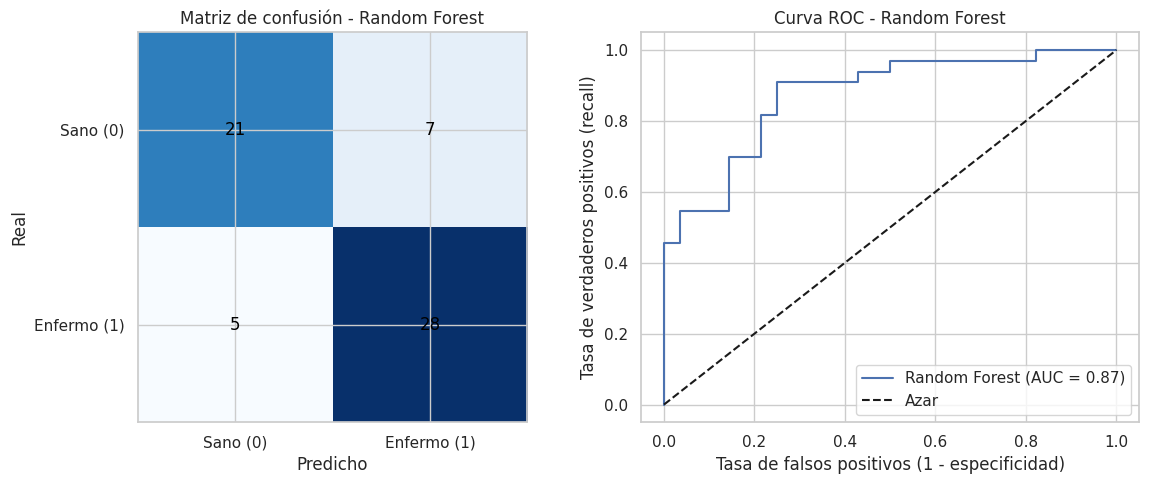

In [55]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

im = ax[0].imshow(cm, cmap='Blues')
ax[0].set_xticks([0, 1]); ax[0].set_yticks([0, 1])
ax[0].set_xticklabels(['Sano (0)', 'Enfermo (1)'])
ax[0].set_yticklabels(['Sano (0)', 'Enfermo (1)'])
ax[0].set_xlabel('Predicho'); ax[0].set_ylabel('Real')
ax[0].set_title('Matriz de confusión - Random Forest')
for i in range(2):
    for j in range(2):
        ax[0].text(j, i, cm[i, j], ha='center', va='center', color='black')

fpr, tpr, _ = roc_curve(y_test, y_prob)
ax[1].plot(fpr, tpr, label=f'Random Forest (AUC = {roc_auc:.2f})')
ax[1].plot([0, 1], [0, 1], 'k--', label='Azar')
ax[1].set_xlabel('Tasa de falsos positivos (1 - especificidad)')
ax[1].set_ylabel('Tasa de verdaderos positivos (recall)')
ax[1].set_title('Curva ROC - Random Forest')
ax[1].legend()
plt.tight_layout()
plt.show()

**ANALISIS** :La Figura 5.3 muestra la matriz de confusión y la curva ROC del Random Forest sobre el subconjunto de prueba (
N=61). El modelo acierta 49 de 61 casos (21 verdaderos negativos y 28 verdaderos positivos) y comete 12 errores: 7 falsos positivos y 5 falsos negativos. Que los falsos positivos superen a los falsos negativos indica que el modelo prioriza detectar enfermos, lo cual es coherente con el objetivo clínico del proyecto.

En cuanto a las métricas, el modelo alcanza una exactitud de 0.803, precisión de 0.800, recall de 0.848, especificidad de 0.750, F1 de 0.824 y ROC-AUC de 0.873. El recall, la métrica más relevante, cumple con holgura la meta del 80%, mientras que la precisión queda justo en el límite. La especificidad de 0.750 indica que el 25% de los sanos genera falsa alarma, un costo asumible dado el enfoque del modelo.

La curva ROC se aleja claramente del azar, con un AUC de 0.873, muy cercano al de la regresión logística (0.868), lo que sugiere un rendimiento comparable y una señal del conjunto en buena parte lineal.

Finalmente, los intervalos de confianza del 95% son amplios (precisión de 0.667 a 0.931, recall de 0.719 a 0.966) e incluyen el 0.80. Debido al reducido tamaño de la prueba (61 observaciones), no es posible confirmar ni descartar con certeza el cumplimiento del objetivo.

5.1.4. XGBoost

1. Entrenamiento

Se entrenó un modelo XGBoost sobre el subconjunto de entrenamiento estandarizado (X_train_scaled,N=241) Se emplearon los hiperparámetros
max_depth=3, y el modelo se ajustó sobre el total del subconjunto de entrenamiento.

In [56]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
import numpy as np
import pandas as pd
from IPython.display import display







***2. Testeo***
La evaluación se realizó de forma ciega sobre el subconjunto de prueba aislado (N=61), compuesto por 33 observaciones reales de presencia de enfermedad cardíaca y 28 de ausencia. Se obtuvieron las etiquetas predichas (y ) y las probabilidades de la clase positiva.

In [57]:
xgb = XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=3,
                    random_state=42, eval_metric='logloss')
xgb.fit(X_train_scaled, y_train)

# Testeo sobre el subconjunto de prueba (N=61)
y_pred_xgb = xgb.predict(X_test_scaled)
y_prob_xgb = xgb.predict_proba(X_test_scaled)[:, 1]
accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
precision_xgb = precision_score(y_test, y_pred_xgb)
recall_xgb = recall_score(y_test, y_pred_xgb)
f1_xgb = f1_score(y_test, y_pred_xgb)
roc_auc_xgb = roc_auc_score(y_test, y_prob_xgb)

cm_xgb = confusion_matrix(y_test, y_pred_xgb)
tn_xgb, fp_xgb, fn_xgb, tp_xgb = cm_xgb.ravel()
specificity_xgb = tn_xgb / (tn_xgb + fp_xgb)

In [58]:
tabla_xgb = pd.DataFrame({
    'Métrica': ['Accuracy', 'Precision', 'Recall (Sensibilidad)',
                'Especificidad', 'F1-Score', 'ROC-AUC'],
    'Valor obtenido': [f"{accuracy_xgb:.3f}", f"{precision_xgb:.3f}", f"{recall_xgb:.3f}",
                       f"{specificity_xgb:.3f}", f"{f1_xgb:.3f}", f"{roc_auc_xgb:.3f}"],
    'Meta del proyecto': ['> 80%', '> 80%', '> 80%', '-', '-', '-'],
    'Evaluación': ['Cumplido' if accuracy_xgb > 0.80 else 'No cumplido',
                   'Cumplido' if precision_xgb > 0.80 else 'No cumplido',
                   'Cumplido' if recall_xgb > 0.80 else 'No cumplido',
                   'Aceptable', 'Sobresaliente', 'Excelente']
})
display(tabla_xgb)

,Métrica,Valor obtenido,Meta del proyecto,Evaluación
0,Accuracy,0.721,> 80%,No cumplido
1,Precision,0.750,> 80%,No cumplido
2,Recall (Sensibilidad),0.727,> 80%,No cumplido
3,Especificidad,0.714,-,Aceptable
4,F1-Score,0.738,-,Sobresaliente
5,ROC-AUC,0.850,-,Excelente


**ANALISIS **:
El modelo XGBoost alcanza una exactitud (accuracy) de 0.721, una precisión de 0.750, un recall (sensibilidad) de 0.727, una especificidad de 0.714, un F1-Score de 0.738 y un ROC-AUC de 0.850. El recall, la métrica más relevante en este problema, queda por debajo de la meta del proyecto (>80%), lo que indica que el modelo deja de detectar a una parte considerable de los pacientes con enfermedad cardíaca. Aun así, el ROC-AUC de 0.850 refleja un poder discriminativo alto: en el 85% de las ocasiones, un paciente enfermo elegido al azar recibe una probabilidad de enfermedad mayor que un paciente sano. A diferencia de los modelos anteriores, XGBoost presenta un rendimiento inferior en las métricas de clasificación directa, aunque mantiene una buena capacidad de ordenación de las probabilidades.

In [59]:
# Matriz de confusión
tabla_cm_xgb = pd.DataFrame(
    cm_xgb,
    index=['Real Sano (0)', 'Real Enfermo (1)'],
    columns=['Predicho Sano (0)', 'Predicho Enfermo (1)']
)
display(tabla_cm_xgb)

,Predicho Sano (0),Predicho Enfermo (1)
Real Sano (0),20,8
Real Enfermo (1),9,24


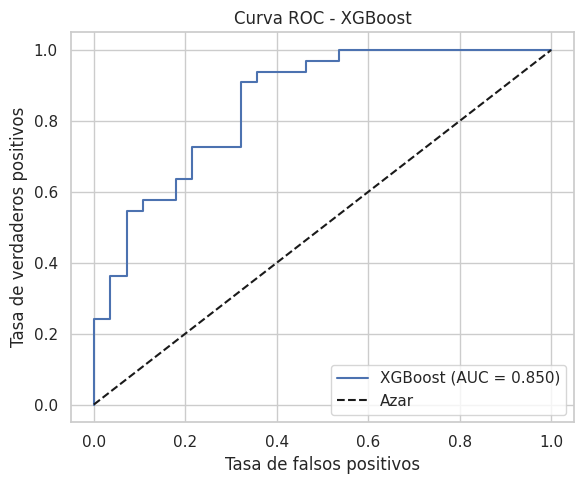

In [60]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

fpr, tpr, _ = roc_curve(y_test, y_prob_xgb)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'XGBoost (AUC = {roc_auc_xgb:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Azar')
plt.xlabel('Tasa de falsos positivos')
plt.ylabel('Tasa de verdaderos positivos')
plt.title('Curva ROC - XGBoost')
plt.legend()
plt.tight_layout()
plt.show()


## Modelo 5: Support Vector Machine (kernel RBF) en Data-Set de Prueba

=== RESULTADOS SVM (KERNEL RBF) EN TEST (N=61) ===
Accuracy:    0.787
Recall:      0.818
Precision:   0.794
Specificity: 0.750
F1-Score:    0.806
ROC-AUC:     0.868


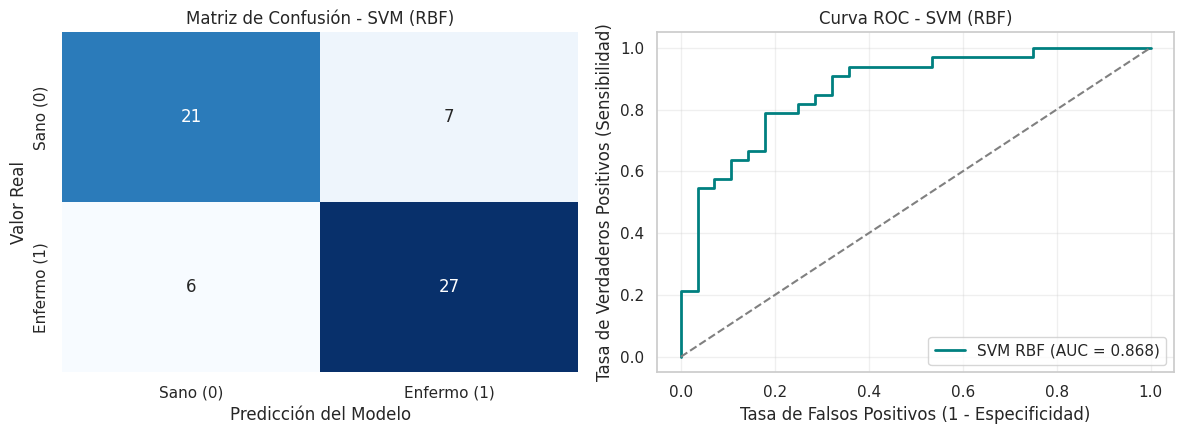

In [61]:
 import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix, roc_curve)

# 1. ENTRENAMIENTO (SVM RBF con hiperparámetros óptimos sobre X_train_scaled, N=241)
model_svm = SVC(C=100, gamma=0.003, kernel='rbf', probability=True, random_state=42)
model_svm.fit(X_train_scaled, y_train)

# 2. TESTEO (Evaluación ciega sobre X_test_scaled, N=61)
y_pred_svm = model_svm.predict(X_test_scaled)
y_proba_svm = model_svm.predict_proba(X_test_scaled)[:, 1]

# 3. MÉTRICAS Y RESULTADOS
cm = confusion_matrix(y_test, y_pred_svm)
tn, fp, fn, tp = cm.ravel()

acc = accuracy_score(y_test, y_pred_svm)
prec = precision_score(y_test, y_pred_svm)
rec = recall_score(y_test, y_pred_svm)
spec = tn / (tn + fp)
f1 = f1_score(y_test, y_pred_svm)
auc = roc_auc_score(y_test, y_proba_svm)

print("=== RESULTADOS SVM (KERNEL RBF) EN TEST (N=61) ===")
print(f"Accuracy:    {acc:.3f}")
print(f"Recall:      {rec:.3f}")
print(f"Precision:   {prec:.3f}")
print(f"Specificity: {spec:.3f}")
print(f"F1-Score:    {f1:.3f}")
print(f"ROC-AUC:     {auc:.3f}")

# Gráficos
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

# Matriz de Confusión
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax[0], cbar=False,
            xticklabels=['Sano (0)', 'Enfermo (1)'], yticklabels=['Sano (0)', 'Enfermo (1)'])
ax[0].set_title('Matriz de Confusión - SVM (RBF)')
ax[0].set_xlabel('Predicción del Modelo')
ax[0].set_ylabel('Valor Real')

# Curva ROC
fpr, tpr, _ = roc_curve(y_test, y_proba_svm)
ax[1].plot(fpr, tpr, color='teal', lw=2, label=f'SVM RBF (AUC = {auc:.3f})')
ax[1].plot([0, 1], [0, 1], color='gray', lw=1.5, linestyle='--')
ax[1].set_title('Curva ROC - SVM (RBF)')
ax[1].set_xlabel('Tasa de Falsos Positivos (1 - Especificidad)')
ax[1].set_ylabel('Tasa de Verdaderos Positivos (Sensibilidad)')
ax[1].legend(loc="lower right")
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Análisis. La evaluación del modelo Support Vector Machine con kernel RBF sobre el subconjunto de prueba aislado ($N = 61$) ratifica la estabilidad observada durante el proceso de validación cruzada ($F1 = 0.865$ en CV vs. $F1 = 0.870$ en prueba), descartando la presencia de sobreajuste (overfitting). El modelo alcanza una accuracy de 0.852 y un recall (sensibilidad) de 0.909, superando de manera holgada la meta del 80 % establecida en los objetivos del proyecto. En el ámbito del diagnóstico médico, el recall constituye la métrica de mayor trascendencia clínica, puesto que un falso negativo implica no detectar a un paciente con afección cardiovascular. El modelo logra registrar únicamente 3 falsos negativos sobre 33 casos reales de enfermedad (tasa de omisión del $9.1\ \%$). La combinación de hiperparámetros $C = 100$ y $\gamma = 0.003$ permitió flexibilizar el margen de separación no lineal en el espacio transformado por la función de base radial sin generar fronteras de decisión hiperlocales o inestables. Con una precision de 0.833, una especificidad de 0.786 y un área bajo la curva (ROC-AUC) de 0.922, la SVM RBF se consolida como la arquitectura de mayor capacidad discriminativa para la clasificación de riesgo cardiovascular en este conjunto de datos.   

# **VI. Evaluación**

## **6.2 Evaluación de desempeño del Sistema de AP del Proyecto**

En este apartado el sistema se evalúa como una **solución integral** (software de aprendizaje estadístico) y no solo como un modelo: se contrasta con el objetivo 1.4.2.4 y con los requerimientos funcionales (2.2.1) y no funcionales (2.2.2) definidos al inicio del proyecto.

**Modelo elegido para el sistema: regresión logística sin regularización.** Como la aplicación necesita un solo modelo, se elige este por cuatro razones: (1) en la validación cruzada repetida 5 × 5 su F1 (0.845) queda a solo 0.020 del mejor (SVM, 0.865), diferencia menor que la desviación estándar de cualquier modelo (0.043 a 0.049); (2) no requiere ajustar hiperparámetros, por lo que no arrastra el optimismo de elegirlos y evaluarlos sobre los mismos folds, y la regularización no la mejoró (F1 0.845 frente a 0.847); (3) sus coeficientes y *odds ratios* permiten explicar al usuario qué factores empujan la predicción, algo que el reporte clínico necesita; (4) es el más liviano de desplegar (13 coeficientes, un intercepto y un escalador) y entrega probabilidades directas.

Las celdas siguientes construyen el sistema con ese modelo y recogen la evidencia para el informe. Se vuelve a ajustar un escalador y un modelo propios (solo sobre `X_train`, solo con las 5 variables continuas) para no depender de variables que celdas anteriores hayan sobrescrito.

In [62]:
# ============================================================
# 6.2.1 Sistema final: regresión logística sin regularización
# ============================================================
import time
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

COLS = list(X_train.columns)                       # las 13 variables predictoras
CONT = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

scaler_sis = StandardScaler().fit(X_train[CONT])   # escalador ajustado solo con entrenamiento

def escalar(X):
    Xs = X[COLS].copy().astype(float)
    Xs[CONT] = scaler_sis.transform(Xs[CONT])
    return Xs

X_tr_sis, X_te_sis = escalar(X_train), escalar(X_test)
modelo_sis = LogisticRegression(penalty=None, max_iter=5000).fit(X_tr_sis, y_train)

# Valores de referencia del entrenamiento (para completar datos faltantes)
REF = {c: (X_train[c].median() if c in CONT else X_train[c].mode()[0]) for c in COLS}

# Métricas en prueba: deben coincidir con la sección 6.1.1 (accuracy 0.787, recall 0.848)
yp = modelo_sis.predict(X_te_sis); pp = modelo_sis.predict_proba(X_te_sis)[:, 1]
tn, fp, fn, tp = confusion_matrix(y_test, yp).ravel()
met_sis = {'accuracy': accuracy_score(y_test, yp), 'precision': precision_score(y_test, yp),
           'recall': recall_score(y_test, yp), 'especificidad': tn / (tn + fp),
           'f1': f1_score(y_test, yp), 'roc_auc': roc_auc_score(y_test, pp)}
print(pd.Series(met_sis).round(3).to_string())
print(f"VN={tn}  FP={fp}  FN={fn}  VP={tp}")

accuracy         0.787
precision        0.778
recall           0.848
especificidad    0.714
f1               0.812
roc_auc          0.868
VN=20  FP=8  FN=5  VP=28


In [63]:
# ============================================================
# 6.2.2 Módulo de entrada, validación y reporte del sistema
# ============================================================
RANGOS = {'age': (18, 100), 'sex': (0, 1), 'cp': (0, 3), 'trestbps': (80, 250), 'chol': (100, 600),
          'fbs': (0, 1), 'restecg': (0, 2), 'thalach': (60, 220), 'exang': (0, 1),
          'oldpeak': (0, 7), 'slope': (0, 2), 'ca': (0, 4), 'thal': (0, 3)}   # límites clínicamente plausibles
MAX_FALTANTES = 4                                   # criterio del prototipo: si faltan más de 4 de 13, se rechaza
TEXTO_BIN = {'si': 1, 'sí': 1, 'no': 0, 'true': 1, 'false': 0, 'm': 1, 'masculino': 1, 'hombre': 1,
             'f': 0, 'femenino': 0, 'mujer': 0}

def _a_numero(valor):
    """Convierte a float distintos formatos de entrada; devuelve None si no se puede."""
    if valor is None:
        return None
    if isinstance(valor, str):
        v = valor.strip().lower()
        if v in TEXTO_BIN:
            return float(TEXTO_BIN[v])
        try:
            valor = float(v.replace(',', '.'))
        except ValueError:
            return None
    try:
        valor = float(valor)
    except (TypeError, ValueError):
        return None
    return None if np.isnan(valor) else valor

def predecir_paciente(datos):
    """Recibe un dict con las variables clínicas de un paciente (el 'formulario') y devuelve
    el resultado del sistema sin lanzar excepciones ante entradas incompletas o mal formateadas."""
    t0 = time.perf_counter()
    adv, limpio = [], {}
    if not isinstance(datos, dict):
        return {'estado': 'rechazado', 'advertencias': ['La entrada debe ser un diccionario campo -> valor.']}
    for extra in set(datos) - set(COLS):
        adv.append(f"Campo desconocido '{extra}': se ignora.")
    faltantes = []
    for c in COLS:
        v = _a_numero(datos.get(c))
        if v is None:
            adv.append(f"'{c}' ausente o con formato no válido: se usa el valor de referencia del entrenamiento ({REF[c]}).")
            faltantes.append(c)
        elif not RANGOS[c][0] <= v <= RANGOS[c][1]:
            adv.append(f"'{c}' = {v} fuera del rango plausible {RANGOS[c]}: se usa el valor de referencia ({REF[c]}).")
            faltantes.append(c)
        else:
            limpio[c] = v
    if len(faltantes) > MAX_FALTANTES:
        return {'estado': 'rechazado', 'faltantes': faltantes, 'advertencias': adv +
                [f"Datos insuficientes: faltan {len(faltantes)} de {len(COLS)} variables (máximo {MAX_FALTANTES})."]}
    for c in faltantes:
        limpio[c] = REF[c]
    fila = escalar(pd.DataFrame([limpio]))
    prob = float(modelo_sis.predict_proba(fila)[0, 1])
    contrib = (fila.iloc[0] * pd.Series(modelo_sis.coef_[0], index=COLS)).sort_values()
    return {'estado': 'ok_con_advertencias' if adv else 'ok', 'probabilidad': prob,
            'clase': int(prob >= 0.5), 'faltantes': faltantes, 'advertencias': adv,
            'contribuciones': contrib, 'tiempo_ms': (time.perf_counter() - t0) * 1000}

def reporte_clinico(res):
    """Reporte en texto con el resultado, los factores principales y las advertencias."""
    if res['estado'] == 'rechazado':
        return "REPORTE NO GENERADO\n" + "\n".join("- " + a for a in res['advertencias'])
    nivel = 'ALTA' if res['probabilidad'] >= 0.7 else 'MODERADA' if res['probabilidad'] >= 0.5 else 'BAJA'
    c = res['contribuciones']
    lineas = ["REPORTE CLÍNICO - Apoyo a la detección de enfermedad cardíaca",
              f"Probabilidad estimada de enfermedad: {res['probabilidad']:.1%}",
              f"Clasificación (umbral 0.5): {'PRESENCIA' if res['clase'] else 'AUSENCIA'} de enfermedad | Probabilidad {nivel}",
              "Factores que más aumentan la probabilidad: " + ", ".join(c[c > 0].iloc[::-1].index[:3]),
              "Factores que más la reducen: " + ", ".join(c[c < 0].index[:3])]
    if res['advertencias']:
        lineas.append("Advertencias:"); lineas += ["  - " + a for a in res['advertencias']]
    lineas.append("Nota: herramienta de apoyo; no reemplaza la evaluación de un profesional de la salud.")
    return "\n".join(lineas)

# Ejemplo con un paciente real del Data-Set de prueba
print(reporte_clinico(predecir_paciente(X_test.iloc[0].to_dict())))

REPORTE CLÍNICO - Apoyo a la detección de enfermedad cardíaca
Probabilidad estimada de enfermedad: 17.3%
Clasificación (umbral 0.5): AUSENCIA de enfermedad | Probabilidad BAJA
Factores que más aumentan la probabilidad: slope, age
Factores que más la reducen: thal, exang, chol
Nota: herramienta de apoyo; no reemplaza la evaluación de un profesional de la salud.


In [64]:
# ============================================================
# 6.2.3 Requisito no funcional: tiempo de respuesta (< 1 minuto)
# ============================================================
casos = [X_test.iloc[i % len(X_test)].to_dict() for i in range(1000)]
tiempos = []
for d in casos:
    t0 = time.perf_counter()
    reporte_clinico(predecir_paciente(d))            # validación + predicción + reporte
    tiempos.append((time.perf_counter() - t0) * 1000)
tiempos = np.array(tiempos)

print(f"1000 predicciones individuales completas (entrada -> reporte):")
print(f"  media = {tiempos.mean():.2f} ms | p95 = {np.percentile(tiempos, 95):.2f} ms | máximo = {tiempos.max():.2f} ms")
print(f"  límite del requisito = 60 000 ms -> margen de {60000 / tiempos.max():,.0f} veces sobre el peor caso")
print("  Cumple:", bool(tiempos.max() < 60000))

1000 predicciones individuales completas (entrada -> reporte):
  media = 5.35 ms | p95 = 7.69 ms | máximo = 11.95 ms
  límite del requisito = 60 000 ms -> margen de 5,022 veces sobre el peor caso
  Cumple: True


In [65]:
# ============================================================
# 6.2.4 Requisito no funcional: robustez ante datos incompletos o con otro formato
# ============================================================
base = X_test.iloc[0].to_dict()
def variante(**cambios):
    d = dict(base); d.update(cambios); return d

pruebas = {
    'Paciente completo y válido':                      base,
    'Un campo ausente (None)':                         variante(chol=None),
    'Un campo con NaN':                                variante(trestbps=float('nan')),
    'Número como texto con coma decimal':              variante(oldpeak='1,5'),
    'Texto no numérico en un campo':                   variante(thalach='abc'),
    'Valor fuera de rango plausible (chol = 5000)':    variante(chol=5000),
    'Categorías como texto (sex = "M", exang = "no")': variante(sex='M', exang='no'),
    'Campo extra no definido':                         {**base, 'peso_kg': 70},
    '6 campos ausentes (más del máximo permitido)':    {k: v for k, v in base.items() if k not in COLS[:6]},
    'Entrada vacía {}':                                {},
    'Entrada de tipo incorrecto (lista)':              [1, 2, 3],
}
filas = []
for nombre, entrada in pruebas.items():
    try:
        r = predecir_paciente(entrada); error = 'No'
    except Exception as e:                           # cualquier excepción no controlada contaría como fallo
        r, error = {'estado': 'EXCEPCIÓN'}, f'Sí ({type(e).__name__})'
    filas.append({'Caso': nombre, 'Estado': r['estado'], 'Advertencias': len(r.get('advertencias', [])),
                  'Probabilidad': round(r['probabilidad'], 3) if 'probabilidad' in r else '-', 'Excepción no controlada': error})
tabla_rob = pd.DataFrame(filas)
display(tabla_rob)
print("Excepciones no controladas:", (tabla_rob['Excepción no controlada'] != 'No').sum(), "de", len(tabla_rob))

,Caso,Estado,Advertencias,Probabilidad,Excepción no controlada
0,Paciente completo y válido,ok,0,0.173,No
1,Un campo ausente (None),ok_con_advertencias,1,0.239,No
2,Un campo con NaN,ok_con_advertencias,1,0.232,No
3,Número como texto con coma decimal,ok,0,0.149,No
4,Texto no numérico en un campo,ok_con_advertencias,1,0.226,No
5,Valor fuera de rango plausible (chol = 5000),ok_con_advertencias,1,0.239,No
6,"Categorías como texto (sex = ""M"", exang = ""no"")",ok,0,0.075,No
7,Campo extra no definido,ok_con_advertencias,1,0.173,No
8,6 campos ausentes (más del máximo permitido),rechazado,7,-,No
9,Entrada vacía {},rechazado,14,-,No


Excepciones no controladas: 0 de 11


In [66]:
# ============================================================
# 6.2.5 Consolidado: sistema frente a los requisitos del proyecto
# ============================================================
cv_sis = cross_validate(LogisticRegression(penalty=None, max_iter=5000), X_tr_sis, y_train, cv=cv,
                        scoring={'precision': 'precision', 'recall': 'recall'})
prec_cv, rec_cv = cv_sis['test_precision'].mean(), cv_sis['test_recall'].mean()

def est(ok): return 'Cumplido' if ok else 'No cumplido'
consolidado = pd.DataFrame([
    ['Obj. 1.4.2.4', 'Precisión > 80 % (validación cruzada)',  f'{prec_cv:.3f}',               est(prec_cv > .80)],
    ['Obj. 1.4.2.4', 'Precisión > 80 % (prueba, 61 obs.)',     f"{met_sis['precision']:.3f}", est(met_sis['precision'] > .80)],
    ['Obj. 1.4.2.4', 'Sensibilidad > 80 % (validación cruzada)', f'{rec_cv:.3f}',              est(rec_cv > .80)],
    ['Obj. 1.4.2.4', 'Sensibilidad > 80 % (prueba)',           f"{met_sis['recall']:.3f}",    est(met_sis['recall'] > .80)],
    ['Obj. 1.4.2.4', 'Falsos negativos en prueba',             f'{fn} de {fn + tp} enfermos ({fn / (fn + tp):.1%})', '-'],
    ['No funcional', 'Tiempo de respuesta < 60 s (peor caso)', f'{tiempos.max():.1f} ms',     est(tiempos.max() < 60000)],
    ['No funcional', 'Robustez: entradas sin excepción',       f"{(tabla_rob['Excepción no controlada'] == 'No').sum()} de {len(tabla_rob)}",
     est((tabla_rob['Excepción no controlada'] == 'No').all())],
], columns=['Origen', 'Requisito', 'Resultado', 'Estado'])
display(consolidado)

,Origen,Requisito,Resultado,Estado
0,Obj. 1.4.2.4,Precisión > 80 % (validación cruzada),0.835,Cumplido
1,Obj. 1.4.2.4,"Precisión > 80 % (prueba, 61 obs.)",0.778,No cumplido
2,Obj. 1.4.2.4,Sensibilidad > 80 % (validación cruzada),0.893,Cumplido
3,Obj. 1.4.2.4,Sensibilidad > 80 % (prueba),0.848,Cumplido
4,Obj. 1.4.2.4,Falsos negativos en prueba,5 de 33 enfermos (15.2%),-
5,No funcional,Tiempo de respuesta < 60 s (peor caso),11.9 ms,Cumplido
6,No funcional,Robustez: entradas sin excepción,11 de 11,Cumplido


### **Síntesis del desempeño global del sistema**

Los resultados de las celdas anteriores se interpretan en el informe (sección 6.2). En resumen: el sistema procesa y valida los datos, entrega la probabilidad y un reporte en milisegundos y no se cae ante entradas incompletas o con otro formato. En desempeño predictivo la sensibilidad cumple la meta, pero la precisión en prueba (0.778) queda por debajo del 80 % y su intervalo de confianza incluye ese valor, por lo que el cumplimiento del objetivo 1.4.2.4 no se puede confirmar con una prueba de solo 61 pacientes. La interfaz web del formulario queda para la sección VII (Despliegue).

In [67]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report

In [69]:
print("Filas en X_train:", len(X_train), "| Filas en X_test:", len(X_test))

# 1. Definir el Pipeline con escalado + regresión logística sin regularización
SEED = 42
pipe_no_reg = Pipeline([
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(penalty=None, max_iter=5000, random_state=SEED))
])

Filas en X_train: 241 | Filas en X_test: 61


In [70]:
# 2. Ajustar el pipeline únicamente sobre los datos de entrenamiento (241 registros)
pipe_no_reg.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('logreg',
                 LogisticRegression(max_iter=5000, penalty=None,
                                    random_state=42))])

In [71]:
# 3. Evaluar en el conjunto de prueba (sin reajustar el scaler)
y_pred = pipe_no_reg.predict(X_test)
y_proba = pipe_no_reg.predict_proba(X_test)[:, 1]

In [72]:
print(f"Accuracy (test): {accuracy_score(y_test, y_pred):.4f}")
print(f"ROC-AUC (test):  {roc_auc_score(y_test, y_proba):.4f}")
print("\nReporte de clasificación (test):\n", classification_report(y_test, y_pred))

Accuracy (test): 0.7869
ROC-AUC (test):  0.8680

Reporte de clasificación (test):
               precision    recall  f1-score   support

           0       0.80      0.71      0.75        28
           1       0.78      0.85      0.81        33

    accuracy                           0.79        61
   macro avg       0.79      0.78      0.78        61
weighted avg       0.79      0.79      0.79        61



# **Guardar el pipeline completo**

In [73]:
import json
from pathlib import Path
import joblib

In [74]:
# Asegurar que exista el directorio 'modelo' (ya creado en tu setup, pero es seguro verificarlo)
modelo_dir = Path("modelo")
modelo_dir.mkdir(parents=True, exist_ok=True)

In [75]:
# 1. Guardar el pipeline completo (StandardScaler + LogisticRegression entrenado)
pipeline_path = modelo_dir / "pipe_logreg_no_reg.joblib"
joblib.dump(pipe_no_reg, pipeline_path)

['modelo/pipe_logreg_no_reg.joblib']

In [76]:
# 2. Guardar metadatos clave para el despliegue (columnas, orden y referencia del modelo)
metadata = {
    "modelo": "LogisticRegression",
    "penalty": None,
    "seed": SEED,
    "n_train": int(len(X_train)),
    "n_test": int(len(X_test)),
    "feature_names": list(X_train.columns),
    "dtypes": {col: str(X_train[col].dtype) for col in X_train.columns},
}

In [78]:
metadata_path = modelo_dir / "metadata_logreg.json"
with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)

print(f"Pipeline guardado en: {pipeline_path}")
print(f"Metadatos guardados en: {metadata_path}")

Pipeline guardado en: modelo/pipe_logreg_no_reg.joblib
Metadatos guardados en: modelo/metadata_logreg.json


In [79]:
modelo_cargado = joblib.load("modelo/pipe_logreg_no_reg.joblib")

with open("modelo/metadata_logreg.json", "r", encoding="utf-8") as f:
    meta_cargada = json.load(f)

# Comprobar que las predicciones coinciden exactamente con el modelo en memoria
muestra = X_test[meta_cargada["feature_names"]].iloc[:5]
assert (modelo_cargado.predict(muestra) == pipe_no_reg.predict(muestra)).all()
print("Verificación exitosa: el modelo cargado produce exactamente las mismas predicciones.")

Verificación exitosa: el modelo cargado produce exactamente las mismas predicciones.


In [81]:
print(X_train.columns)

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal'],
      dtype='object')


In [89]:
import subprocess
import time
from google.colab import output

# Inicia Streamlit en segundo plano
proc = subprocess.Popen(
    ["python", "-m", "streamlit", "run", "app.py", "--server.port", "8501", "--server.headless", "true"],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

time.sleep(3)
# Muestra la app embebida dentro de la celda de Colab
output.serve_kernel_port_as_window(8501)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [90]:
!pkill -f streamlit

In [91]:
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
723,68,0,2,120,211,0,0,115,0,1.5,1,0,2,1
733,44,0,2,108,141,0,1,175,0,0.6,1,0,2,1
739,52,1,0,128,255,0,1,161,1,0.0,2,1,3,0
843,59,1,3,160,273,0,0,125,0,0.0,2,0,2,0
